# Binaries and the Kepler Radius Valley — Fulton-filtered catalogue comparison

**Goal.** Reconstruct the small-planet radius distributions for (1) Kepler DR25 confirmed planets, (2) the published Fulton et al. (2017) selected sample, (3) CKS planet radii, and (4) Sullivan et al. (2024) binary-host planets. Apply a consistent *Fulton-like* selection to DR25, CKS, and Sullivan, then compare histograms with KDE curves.

## Population definitions

- **DR25 reference:** confirmed DR25 planets, with Sullivan-listed binary systems removed for the principal single-star reference. The all-confirmed DR25 sample is retained as a diagnostic.
- **Fulton 2017:** VizieR `J/AJ/154/109/table2`. The catalogue ReadMe states that this 900-row table already contains detections that passed the filters in Section 2.2. The table does not carry all stellar/transit columns needed to reapply each cut, so it is treated as the *published Fulton-selected sample* and its available radius/period bounds are rechecked.
- **CKS:** full CKS planet table joined to CKS stellar parameters, then filtered using the same available criteria as in the previous project notebook.
- **Sullivan:** Sullivan 2024 planet and system tables joined to DR25 transit metadata. Two samples are retained: DR25-confirmed planets only, and DR25 candidate+confirmed planets. The stellar dwarf cut is applied to the Sullivan primary-star parameters, as in the existing `Binaries_Gap_Complete_Analysis` notebook.

**Terminology check:** “confirmed” in this notebook means the *Kepler planet disposition* from DR25. It is not a separate confirmation flag for the stellar binary itself. Planet counts and unique binary-system counts are always printed separately. This lets us check a reported `92` without conflating planets and systems.

## Fulton-like cuts used where columns exist

1. Planet radius: 0.5–20 Earth radii (selection domain; plots show 0.5–4 Earth radii).
2. Kepler magnitude: `Kp < 14.2`.
3. Transit impact parameter: `0 <= b < 0.7`.
4. Orbital period: `0 < P < 100` days.
5. Dwarf/evolved-star boundary: `Rstar <= 10**(0.00025*(Teff - 5500) + 0.20)` in solar radii.
6. Effective temperature: `4700 < Teff < 6500` K.

For DR25, the host-star parameters are DR25 values. For CKS, stellar `Teff` and radius are from CKS Table 1 while magnitude, impact parameter, period and disposition are joined from DR25. For Sullivan, the stellar cut uses `Teff1` and `Rstar1` (primary star), while transit metadata and planet disposition come from DR25. This is the documented adaptation already used in the project; it is not an exact reproduction of the full CKS spectroscopic selection.

**Important:** These are detected-planet radius distributions, not completeness-corrected occurrence rates.

## 1. Imports, project paths, and settings

In [1]:
from pathlib import Path
import io
import re
import time
import urllib.parse
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from IPython.display import display

# ---- Locate project root. Override PROJECT_ROOT manually if required. ----
PROJECT_ROOT = None  # e.g. Path('/home/USER/Downloads/Binaries')


def find_project_root(start=Path.cwd()):
    if PROJECT_ROOT is not None:
        return Path(PROJECT_ROOT).expanduser().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'raw').exists():
            return candidate.resolve()
    # Common local project locations; edit if your folder is elsewhere.
    candidates = [
        Path.home() / 'Downloads' / 'Binaries',
        Path.home() / 'Downloads' / 'binaries',
        Path.home() / 'Binaries',
    ]
    for candidate in candidates:
        if (candidate / 'data' / 'raw').exists():
            return candidate.resolve()
    return Path.cwd().resolve()

ROOT = find_project_root()
RAW = ROOT / 'data' / 'raw'
REFERENCE = ROOT / 'data' / 'reference'
OUTPUT = ROOT / 'outputs' / 'fulton_filtered_distribution_comparison'
OUTPUT.mkdir(parents=True, exist_ok=True)

DR25_FILE = RAW / 'nasa' / 'nasa_kepler_dr25_koi.csv'
SULLIVAN_PLANETS_FILE = RAW / 'sullivan' / 'sullivan_planet_table.csv'
SULLIVAN_STARS_FILE = RAW / 'sullivan' / 'sullivan_sample_table.csv'

# Fulton et al. 2017 (Paper III), CKS Paper II tables.
FULTON_CACHE = REFERENCE / 'fulton_2017'
CKS_CACHE = REFERENCE / 'cks_2017'
FULTON_CACHE.mkdir(parents=True, exist_ok=True)
CKS_CACHE.mkdir(parents=True, exist_ok=True)
FULTON_PATH = FULTON_CACHE / 'table2.tsv'
CKS_PLANET_PATH = CKS_CACHE / 'table4.tsv'
CKS_STAR_PATH = CKS_CACHE / 'table1.tsv'

# Shared selection/plot configuration.
RADIUS_MIN, RADIUS_MAX = 0.5, 20.0
PLOT_RMIN, PLOT_RMAX = 0.5, 4.0
KP_MAX = 14.2
IMPACT_MAX = 0.7
PERIOD_MAX = 100.0
TEFF_MIN, TEFF_MAX = 4700.0, 6500.0
N_BINS = 24
N_GRID = 600
KDE_BANDWIDTH_FACTOR = 1.0

print('Project root:', ROOT)
print('Output directory:', OUTPUT)
for p in [DR25_FILE, SULLIVAN_PLANETS_FILE, SULLIVAN_STARS_FILE]:
    print(('FOUND ' if p.is_file() else 'MISSING '), p)

Project root: C:\Users\Lenovo\Downloads\bin
Output directory: C:\Users\Lenovo\Downloads\bin\outputs\fulton_filtered_distribution_comparison
FOUND  C:\Users\Lenovo\Downloads\bin\data\raw\nasa\nasa_kepler_dr25_koi.csv
FOUND  C:\Users\Lenovo\Downloads\bin\data\raw\sullivan\sullivan_planet_table.csv
FOUND  C:\Users\Lenovo\Downloads\bin\data\raw\sullivan\sullivan_sample_table.csv


## 2. Utility functions and VizieR cache/download

In [2]:
def as_numeric(frame, column):
    if column not in frame.columns:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    return pd.to_numeric(frame[column], errors='coerce')


def normalize_planet_key(value):
    """Normalize K00042.01, 42.01, and numeric-like KOI planet IDs."""
    if pd.isna(value):
        return pd.NA
    match = re.search(r'K?0*(\d+)\s*\.\s*(\d+)', str(value).strip().upper())
    if not match:
        return pd.NA
    return f'{int(match.group(1)):05d}.{int(match.group(2)):02d}'


def normalize_system_key(value):
    if pd.isna(value):
        return pd.NA
    match = re.search(r'(\d+)', str(value).strip())
    return f'{int(match.group(1)):05d}' if match else pd.NA


def system_from_planet_key(key):
    if pd.isna(key):
        return pd.NA
    return str(key).split('.')[0]


def max_dwarf_radius(teff):
    """Fulton et al. (2017) evolved-star boundary, in solar radii."""
    return 10.0 ** (0.00025 * (np.asarray(teff, dtype=float) - 5500.0) + 0.20)


def require_columns(frame, cols, label):
    missing = [c for c in cols if c not in frame.columns]
    if missing:
        raise KeyError(f'{label}: missing {missing}. Available columns: {frame.columns.tolist()}')


def parse_vizier_tsv(raw_text, source):
    lines = []
    for line in raw_text.splitlines():
        stripped = line.strip()
        if not stripped or stripped.startswith('#'):
            continue
        if re.fullmatch(r'[\s\-+|]+', stripped):
            continue
        lines.append(line)
    if len(lines) < 2 or '\t' not in lines[0]:
        raise ValueError(f'{source}: response is not a usable VizieR TSV table.')
    out = pd.read_csv(io.StringIO('\n'.join(lines)), sep='\t', dtype='string', engine='python')
    out.columns = [str(c).strip() for c in out.columns]
    out = out.loc[:, ~out.columns.astype(str).str.match(r'^Unnamed')]
    return out.dropna(how='all').reset_index(drop=True)


VIZIER_MIRRORS = [
    'https://vizier.idia.ac.za',
    'https://vizier.iucaa.ernet.in',
    'https://vizier.cfa.harvard.edu',
    'https://vizier.cds.unistra.fr',
    'https://vizier.nao.ac.jp',
]


def load_vizier_table(cache_path, catalogue_source, timeout=35):
    if cache_path.is_file():
        try:
            table = parse_vizier_tsv(cache_path.read_text(encoding='utf-8', errors='replace'), catalogue_source)
            print(f'Using cached {catalogue_source}: {table.shape}')
            return table
        except Exception as exc:
            warnings.warn(f'Invalid cache {cache_path}; will redownload. Reason: {exc}')
            cache_path.unlink(missing_ok=True)

    params = urllib.parse.urlencode({'-source': catalogue_source, '-out.max': 'unlimited'})
    errors = []
    for mirror in VIZIER_MIRRORS:
        url = f'{mirror}/viz-bin/asu-tsv?{params}'
        try:
            request = urllib.request.Request(
                url,
                headers={'User-Agent': 'Mozilla/5.0 (compatible; Kepler-radius-gap-analysis/1.0)'}
            )
            with urllib.request.urlopen(request, timeout=timeout) as response:
                raw = response.read().decode('utf-8', errors='replace')
            table = parse_vizier_tsv(raw, catalogue_source)
            cache_path.write_text(raw, encoding='utf-8')
            print(f'Downloaded {catalogue_source} from {mirror}: {table.shape}')
            return table
        except Exception as exc:
            errors.append(f'{mirror}: {type(exc).__name__}: {exc}')
            print('VizieR mirror failed:', mirror, type(exc).__name__)
    raise RuntimeError(
        f'Could not retrieve {catalogue_source}. Download the table manually as TSV into {cache_path}.\n'
        + '\n'.join(errors)
    )


def sequential_cut(frame, cuts, sample, system_col='system_key'):
    current = frame.copy()
    records = [{
        'sample': sample, 'stage': 'Input to Fulton-like cuts', 'N_planets': len(current),
        'N_systems': current[system_col].nunique(dropna=True) if system_col in current else np.nan,
        'removed': 0,
    }]
    for label, mask in cuts:
        mask = pd.Series(mask, index=frame.index).reindex(current.index).fillna(False).astype(bool)
        n0 = len(current)
        current = current.loc[mask].copy()
        records.append({
            'sample': sample, 'stage': label, 'N_planets': len(current),
            'N_systems': current[system_col].nunique(dropna=True) if system_col in current else np.nan,
            'removed': n0 - len(current),
        })
    return current, records

print('Helpers ready.')

Helpers ready.


## 3. Load the four source catalogues

In [3]:
# DR25 and Sullivan tables are expected from the upstream project pipeline.
for p in [DR25_FILE, SULLIVAN_PLANETS_FILE, SULLIVAN_STARS_FILE]:
    if not p.is_file():
        raise FileNotFoundError(
            f'Missing required input: {p}\n'
            'Run the upstream data-retrieval notebook or correct PROJECT_ROOT in Section 1.'
        )

dr25_raw = pd.read_csv(DR25_FILE, low_memory=False)
sullivan_planets_raw = pd.read_csv(
    SULLIVAN_PLANETS_FILE, low_memory=False, dtype={'KOI': 'string', 'KOIpl': 'string'}
)
sullivan_stars_raw = pd.read_csv(
    SULLIVAN_STARS_FILE, low_memory=False, dtype={'KOI': 'string'}
)

# VizieR: Fulton et al. 2017 Table 2 (already selected in the published paper),
# and CKS Paper II Tables 1 and 4 (stellar and planet catalogues).
fulton_raw = load_vizier_table(FULTON_PATH, 'J/AJ/154/109/table2')
cks_planets_raw = load_vizier_table(CKS_PLANET_PATH, 'J/AJ/154/108/table4')
cks_stars_raw = load_vizier_table(CKS_STAR_PATH, 'J/AJ/154/108/table1')

print('\nSOURCE SHAPES')
for label, frame in [
    ('DR25', dr25_raw), ('Fulton 2017 Table 2', fulton_raw),
    ('CKS planets Table 4', cks_planets_raw), ('CKS stars Table 1', cks_stars_raw),
    ('Sullivan planets', sullivan_planets_raw), ('Sullivan systems', sullivan_stars_raw),
]:
    print(f'{label:28s} {frame.shape}')

print('\nFulton columns:', fulton_raw.columns.tolist())
print('CKS planet columns:', cks_planets_raw.columns.tolist())
print('CKS stellar columns:', cks_stars_raw.columns.tolist())
print('Sullivan planet columns:', sullivan_planets_raw.columns.tolist())
print('Sullivan system columns:', sullivan_stars_raw.columns.tolist())

Using cached J/AJ/154/109/table2: (901, 17)
Using cached J/AJ/154/108/table4: (2026, 12)
Using cached J/AJ/154/108/table1: (1306, 18)

SOURCE SHAPES
DR25                         (8054, 153)
Fulton 2017 Table 2          (901, 17)
CKS planets Table 4          (2026, 12)
CKS stars Table 1            (1306, 18)
Sullivan planets             (404, 28)
Sullivan systems             (286, 52)

Fulton columns: ['KOI', 'Per', 'E_Per', 'e_Per', 'Rad', 'E_Rad', 'e_Rad', 'S/N', 'DProb', 'TProb', 'Weight', 'M15', 'PapI', 'PapII', 'Simbad', '_RA', '_DE']
CKS planet columns: ['KOI', 'Star', 'Per', 'Rp/R*', 'Rad', 'Sinc', 'Teq', 'M15', 'PapI', 'Simbad', '_RA', '_DE']
CKS stellar columns: ['Name', 'Npl', 'TYC2', 'Ksmag', 'Teff', 'logg', '[Fe/H]', 'Mass', 'Rad', 'logA', 'plx1', 'plx2', 'PapI', 'TGAS', '2M', 'Simbad', '_RA', '_DE']
Sullivan planet columns: ['KOIpl', 'Rppri', 'E_Rppri', 'e_Rppri', 'Rpsec', 'E_Rpsec', 'e_Rpsec', 'Rpkep', 'e_Rpkep', 'Teqpri', 'E_Teqpri', 'e_Teqpri', 'Teqsec', 'E_Teqsec', 'e_T

## 4. Standardize DR25 and construct DR25 confirmed reference

In [4]:
require_columns(dr25_raw, [
    'kepoi_name', 'koi_disposition', 'koi_prad', 'koi_period', 'koi_kepmag',
    'koi_impact', 'koi_steff', 'koi_srad'
], 'DR25')

dr25 = dr25_raw.copy()
dr25['planet_key'] = dr25['kepoi_name'].map(normalize_planet_key).astype('string')
dr25['system_key'] = dr25['planet_key'].map(system_from_planet_key).astype('string')
for source, target in [
    ('koi_prad', 'Rp_DR25'), ('koi_period', 'Period_DR25'), ('koi_kepmag', 'Kp_DR25'),
    ('koi_impact', 'Impact_DR25'), ('koi_steff', 'Teff_DR25'), ('koi_srad', 'Rstar_DR25'),
]:
    dr25[target] = as_numeric(dr25, source)
dr25['Disposition'] = dr25['koi_disposition'].astype('string').str.strip().str.upper()

# Sullivan binary system IDs define the binary-host list to be excluded from
# the main DR25 apparent-single reference distribution.
sullivan_system_key = sullivan_stars_raw['KOI'].map(normalize_system_key).dropna().astype(str)
SULLIVAN_SYSTEM_IDS = set(sullivan_system_key)
dr25['is_Sullivan_binary_system'] = dr25['system_key'].astype('string').isin(SULLIVAN_SYSTEM_IDS)

# Radius domain is applied first, then sequential sample cuts.
dr25_domain = dr25.loc[dr25['Rp_DR25'].between(RADIUS_MIN, RADIUS_MAX)].copy()

def dr25_cuts(frame):
    return [
        ('Kp < 14.2', frame['Kp_DR25'].lt(KP_MAX)),
        ('0 <= impact parameter < 0.7', frame['Impact_DR25'].ge(0) & frame['Impact_DR25'].lt(IMPACT_MAX)),
        ('0 < period < 100 d', frame['Period_DR25'].gt(0) & frame['Period_DR25'].lt(PERIOD_MAX)),
        ('Fulton dwarf/evolved boundary', frame['Rstar_DR25'].gt(0) & frame['Teff_DR25'].notna() & (frame['Rstar_DR25'] <= max_dwarf_radius(frame['Teff_DR25']))),
        ('4700 < Teff < 6500 K', frame['Teff_DR25'].gt(TEFF_MIN) & frame['Teff_DR25'].lt(TEFF_MAX)),
    ]

DR25_confirmed_input = dr25_domain.loc[dr25_domain['Disposition'].eq('CONFIRMED')].copy()
dr25_confirmed_all, dr25_rows = sequential_cut(
    DR25_confirmed_input, dr25_cuts(DR25_confirmed_input), 'DR25 confirmed (all systems)'
)
DR25_confirmed_single = dr25_confirmed_all.loc[~dr25_confirmed_all['is_Sullivan_binary_system']].copy()
DR25_confirmed_binary_overlap = dr25_confirmed_all.loc[dr25_confirmed_all['is_Sullivan_binary_system']].copy()

# Candidate+confirmed DR25 is useful as a disposition sensitivity check.
DR25_candconf_input = dr25_domain.loc[dr25_domain['Disposition'].isin(['CANDIDATE', 'CONFIRMED'])].copy()
DR25_candconf, dr25_candconf_rows = sequential_cut(
    DR25_candconf_input, dr25_cuts(DR25_candconf_input), 'DR25 candidate+confirmed'
)
DR25_CUT_LEDGER = pd.DataFrame(dr25_rows + dr25_candconf_rows)
display(DR25_CUT_LEDGER)

print('DR25 confirmed after cuts:', len(dr25_confirmed_all), 'planets;', dr25_confirmed_all.system_key.nunique(), 'systems')
print('DR25 confirmed non-Sullivan reference:', len(DR25_confirmed_single), 'planets;', DR25_confirmed_single.system_key.nunique(), 'systems')
print('DR25 confirmed overlapping Sullivan binary list:', len(DR25_confirmed_binary_overlap), 'planets;', DR25_confirmed_binary_overlap.system_key.nunique(), 'systems')

,sample,stage,N_planets,N_systems,removed
0,DR25 confirmed (all systems),Input to Fulton-like cuts,2712,1954,0
1,DR25 confirmed (all systems),Kp < 14.2,1058,733,1654
2,DR25 confirmed (all systems),0 <= impact parameter < 0.7,709,537,349
3,DR25 confirmed (all systems),0 < period < 100 d,666,511,43
4,DR25 confirmed (all systems),Fulton dwarf/evolved boundary,626,475,40
5,DR25 confirmed (all systems),4700 < Teff < 6500 K,592,449,34
6,DR25 candidate+confirmed,Input to Fulton-like cuts,3939,2958,0
7,DR25 candidate+confirmed,Kp < 14.2,1502,1093,2437
8,DR25 candidate+confirmed,0 <= impact parameter < 0.7,1022,803,480
9,DR25 candidate+confirmed,0 < period < 100 d,934,735,88


DR25 confirmed after cuts: 592 planets; 449 systems
DR25 confirmed non-Sullivan reference: 520 planets; 395 systems
DR25 confirmed overlapping Sullivan binary list: 72 planets; 54 systems


## 5. Fulton et al. (2017) published selected sample

In [5]:
# Fulton et al. 2017 VizieR table2 columns are KOI, Per, Rad, uncertainties,
# plus S/N, detection/transit probabilities and completeness weight.
# Its ReadMe explicitly says these 900 detections passed the paper's Section 2.2 filters.
require_columns(fulton_raw, ['KOI', 'Per', 'Rad'], 'Fulton 2017 Table 2')
fulton = pd.DataFrame(index=fulton_raw.index)
fulton['planet_key'] = fulton_raw['KOI'].map(normalize_planet_key).astype('string')
fulton['system_key'] = fulton['planet_key'].map(system_from_planet_key).astype('string')
fulton['Rp_Fulton'] = pd.to_numeric(fulton_raw['Rad'], errors='coerce')
fulton['Period_Fulton'] = pd.to_numeric(fulton_raw['Per'], errors='coerce')

# Only reapply cuts whose variables are present in this published table.
fulton_selected, fulton_rows = sequential_cut(
    fulton,
    [
        ('Fulton published-table radius domain: 0.5–20 R_earth', fulton['Rp_Fulton'].between(RADIUS_MIN, RADIUS_MAX)),
        ('0 < period < 100 d (available-column check)', fulton['Period_Fulton'].gt(0) & fulton['Period_Fulton'].lt(PERIOD_MAX)),
    ],
    'Fulton 2017 published filtered sample'
)
FULTON_CUT_LEDGER = pd.DataFrame(fulton_rows)
display(FULTON_CUT_LEDGER)
print('Fulton published sample:', len(fulton_selected), 'planets;', fulton_selected.system_key.nunique(), 'systems')
print('Note: Kp, impact parameter and stellar Teff/radius are not in Table 2; their original Fulton filters cannot be independently re-applied here.')

,sample,stage,N_planets,N_systems,removed
0,Fulton 2017 published filtered sample,Input to Fulton-like cuts,901,652,0
1,Fulton 2017 published filtered sample,Fulton published-table radius domain: 0.5–20 R...,892,650,9
2,Fulton 2017 published filtered sample,0 < period < 100 d (available-column check),892,650,0


Fulton published sample: 892 planets; 650 systems
Note: Kp, impact parameter and stellar Teff/radius are not in Table 2; their original Fulton filters cannot be independently re-applied here.


## 6. Standardize CKS, attach DR25 transit metadata, and apply Fulton-like cuts

In [6]:
def resolve_column(frame, candidates, required=True):
    for name in candidates:
        if name in frame.columns:
            return name
    if required:
        raise KeyError(f'None of {candidates} found. Available: {frame.columns.tolist()}')
    return None

cks_id = resolve_column(cks_planets_raw, ['KOI'])
cks_period = resolve_column(cks_planets_raw, ['Per', 'Period'])
cks_radius = resolve_column(cks_planets_raw, ['Rad', 'Rp', 'R_p'])
cks_star_name = resolve_column(cks_planets_raw, ['Star'])
cks_star_name1 = resolve_column(cks_stars_raw, ['Name'])
cks_teff = resolve_column(cks_stars_raw, ['Teff'])
cks_rstar = resolve_column(cks_stars_raw, ['Rad'])

cks_planets = pd.DataFrame({
    'planet_key': cks_planets_raw[cks_id].map(normalize_planet_key).astype('string'),
    'star_name': cks_planets_raw[cks_star_name].astype('string').str.strip(),
    'Rp_CKS': pd.to_numeric(cks_planets_raw[cks_radius], errors='coerce'),
    'Period_CKS': pd.to_numeric(cks_planets_raw[cks_period], errors='coerce'),
})
cks_stars = pd.DataFrame({
    'star_name': cks_stars_raw[cks_star_name1].astype('string').str.strip(),
    'Teff_CKS': pd.to_numeric(cks_stars_raw[cks_teff], errors='coerce'),
    'Rstar_CKS': pd.to_numeric(cks_stars_raw[cks_rstar], errors='coerce'),
}).dropna(subset=['star_name'])

if cks_stars['star_name'].duplicated().any():
    raise ValueError('CKS Table 1 has duplicate Name keys; inspect before joining.')
if cks_planets['planet_key'].duplicated().any():
    raise ValueError('CKS Table 4 has duplicate normalized KOI planet keys; inspect before joining.')

cks = cks_planets.merge(cks_stars, on='star_name', how='left', validate='many_to_one')
DR25_META = dr25[[
    'planet_key', 'Disposition', 'Period_DR25', 'Kp_DR25', 'Impact_DR25',
    'Rp_DR25', 'system_key'
]].copy()
cks = cks.merge(DR25_META, on='planet_key', how='left', validate='one_to_one')
cks['system_key'] = cks['planet_key'].map(system_from_planet_key).astype('string')
cks['Period_for_cuts'] = cks['Period_DR25'].fillna(cks['Period_CKS'])
cks['Rstar_max_dwarf'] = max_dwarf_radius(cks['Teff_CKS'])

cks_cuts = [
    ('DR25 disposition candidate or confirmed', cks['Disposition'].isin(['CANDIDATE', 'CONFIRMED'])),
    ('CKS radius 0.5–20 R_earth', cks['Rp_CKS'].between(RADIUS_MIN, RADIUS_MAX)),
    ('DR25 Kp < 14.2', cks['Kp_DR25'].lt(KP_MAX)),
    ('DR25 0 <= impact parameter < 0.7', cks['Impact_DR25'].ge(0) & cks['Impact_DR25'].lt(IMPACT_MAX)),
    ('0 < period < 100 d', cks['Period_for_cuts'].gt(0) & cks['Period_for_cuts'].lt(PERIOD_MAX)),
    ('CKS dwarf/evolved boundary', cks['Rstar_CKS'].gt(0) & cks['Rstar_CKS'].le(cks['Rstar_max_dwarf'])),
    ('4700 < CKS Teff < 6500 K', cks['Teff_CKS'].gt(TEFF_MIN) & cks['Teff_CKS'].lt(TEFF_MAX)),
]
cks_selected, cks_rows = sequential_cut(cks, cks_cuts, 'CKS Fulton-like selection')
CKS_CUT_LEDGER = pd.DataFrame(cks_rows)
display(CKS_CUT_LEDGER)
print('CKS planets with DR25 transit match:', int(cks['Kp_DR25'].notna().sum()), '/', len(cks))
print('CKS Fulton-like selected:', len(cks_selected), 'planets;', cks_selected.system_key.nunique(), 'systems')

,sample,stage,N_planets,N_systems,removed
0,CKS Fulton-like selection,Input to Fulton-like cuts,2026,1279,0
1,CKS Fulton-like selection,DR25 disposition candidate or confirmed,1748,1086,278
2,CKS Fulton-like selection,CKS radius 0.5–20 R_earth,1717,1068,31
3,CKS Fulton-like selection,DR25 Kp < 14.2,1158,811,559
4,CKS Fulton-like selection,DR25 0 <= impact parameter < 0.7,782,594,376
5,CKS Fulton-like selection,0 < period < 100 d,731,562,51
6,CKS Fulton-like selection,CKS dwarf/evolved boundary,700,533,31
7,CKS Fulton-like selection,4700 < CKS Teff < 6500 K,689,527,11


CKS planets with DR25 transit match: 1880 / 2026
CKS Fulton-like selected: 689 planets; 527 systems


## 7. Sullivan binary sample: confirmed-only and candidate+confirmed

In [7]:
# Sullivan 2024 planet rows (Table 5) join to system metadata (sample/Table 2),
# then to DR25 by the normalized planet key.
require_columns(sullivan_planets_raw, ['KOIpl', 'KOI', 'Rpkep', 'Rppri', 'Rpsec'], 'Sullivan planet table')
require_columns(sullivan_stars_raw, ['KOI', 'Teff1', 'Rstar1'], 'Sullivan system table')

sullivan_planets = sullivan_planets_raw.copy()
sullivan_planets['planet_key'] = sullivan_planets['KOIpl'].map(normalize_planet_key).astype('string')
sullivan_planets['system_key'] = sullivan_planets['KOI'].map(normalize_system_key).astype('string')
for col in ['Rpkep', 'Rppri', 'Rpsec']:
    sullivan_planets[col] = pd.to_numeric(sullivan_planets[col], errors='coerce')

sullivan_stars = sullivan_stars_raw.copy()
sullivan_stars['system_key'] = sullivan_stars['KOI'].map(normalize_system_key).astype('string')
if sullivan_stars['system_key'].duplicated().any():
    raise ValueError('Sullivan system table is not unique in normalized system_key.')
star_cols = [c for c in sullivan_stars.columns if c not in ['KOI', 'system_key']]
sullivan_binary = sullivan_planets.merge(
    sullivan_stars[['system_key'] + star_cols], on='system_key', how='left', validate='many_to_one'
)

DR25_BINARY_META = dr25[[
    'planet_key', 'Disposition', 'Period_DR25', 'Kp_DR25', 'Impact_DR25',
    'Teff_DR25', 'Rstar_DR25', 'Rp_DR25'
]].copy()
sullivan_binary = sullivan_binary.merge(
    DR25_BINARY_META, on='planet_key', how='left', validate='many_to_one'
)
sullivan_binary['Teff_primary'] = pd.to_numeric(sullivan_binary['Teff1'], errors='coerce')
sullivan_binary['Rstar_primary'] = pd.to_numeric(sullivan_binary['Rstar1'], errors='coerce')
sullivan_binary['Rstar_max_dwarf_primary'] = max_dwarf_radius(sullivan_binary['Teff_primary'])

# Initial radius gate uses the Sullivan Kepler-catalogue radius Rpkep, following
# the existing project notebook. Rppri/Rpsec are alternative host-dependent radii,
# and are not counted as additional planets.
sullivan_domain = sullivan_binary.loc[
    sullivan_binary['Rpkep'].between(RADIUS_MIN, RADIUS_MAX)
].copy()

sullivan_cuts = [
    ('DR25 disposition candidate or confirmed', sullivan_domain['Disposition'].isin(['CANDIDATE', 'CONFIRMED'])),
    ('DR25 Kp < 14.2', sullivan_domain['Kp_DR25'].lt(KP_MAX)),
    ('DR25 0 <= impact parameter < 0.7', sullivan_domain['Impact_DR25'].ge(0) & sullivan_domain['Impact_DR25'].lt(IMPACT_MAX)),
    ('0 < DR25 period < 100 d', sullivan_domain['Period_DR25'].gt(0) & sullivan_domain['Period_DR25'].lt(PERIOD_MAX)),
    ('Primary-star dwarf/evolved boundary', sullivan_domain['Rstar_primary'].gt(0) & sullivan_domain['Teff_primary'].notna() & (sullivan_domain['Rstar_primary'] <= sullivan_domain['Rstar_max_dwarf_primary'])),
    ('4700 < primary Teff < 6500 K', sullivan_domain['Teff_primary'].gt(TEFF_MIN) & sullivan_domain['Teff_primary'].lt(TEFF_MAX)),
]
sullivan_selected, sullivan_rows = sequential_cut(
    sullivan_domain, sullivan_cuts, 'Sullivan candidate+confirmed (Fulton-like)'
)

# These are the two subsets requested: confirmed-only, and all confirmed+candidate.
sullivan_confirmed = sullivan_selected.loc[sullivan_selected['Disposition'].eq('CONFIRMED')].copy()
sullivan_candidate_confirmed = sullivan_selected.loc[
    sullivan_selected['Disposition'].isin(['CANDIDATE', 'CONFIRMED'])
].copy()
sullivan_candidate_only = sullivan_selected.loc[sullivan_selected['Disposition'].eq('CANDIDATE')].copy()

SULLIVAN_CUT_LEDGER = pd.DataFrame(sullivan_rows)
display(SULLIVAN_CUT_LEDGER)

# Count planets and systems independently. This is the key check against 92 vs 172.
def report_population(label, frame):
    print(f'{label:43s}: {len(frame):4d} planet rows | {frame.system_key.nunique():4d} binary systems')

print('\nSULLIVAN COUNTS AFTER FILTERING')
report_population('Sullivan confirmed-only', sullivan_confirmed)
report_population('Sullivan candidate-only', sullivan_candidate_only)
report_population('Sullivan candidate+confirmed', sullivan_candidate_confirmed)
print('\nDisposition counts (planet rows):')
print(sullivan_selected['Disposition'].value_counts(dropna=False))

# Flag whether the requested target counts are reproduced; do not force them.
print('\nReference-count diagnostic:')
print('Confirmed-only target mentioned by user: 92')
print('Candidate+confirmed parent mentioned by user: 172')
print('Compare these to the planet-row and system counts above; do not equate the two units.')

,sample,stage,N_planets,N_systems,removed
0,Sullivan candidate+confirmed (Fulton-like),Input to Fulton-like cuts,396,285,0
1,Sullivan candidate+confirmed (Fulton-like),DR25 disposition candidate or confirmed,356,259,40
2,Sullivan candidate+confirmed (Fulton-like),DR25 Kp < 14.2,170,123,186
3,Sullivan candidate+confirmed (Fulton-like),DR25 0 <= impact parameter < 0.7,117,91,53
4,Sullivan candidate+confirmed (Fulton-like),0 < DR25 period < 100 d,111,85,6
5,Sullivan candidate+confirmed (Fulton-like),Primary-star dwarf/evolved boundary,111,85,0
6,Sullivan candidate+confirmed (Fulton-like),4700 < primary Teff < 6500 K,90,66,21



SULLIVAN COUNTS AFTER FILTERING
Sullivan confirmed-only                    :   63 planet rows |   46 binary systems
Sullivan candidate-only                    :   27 planet rows |   25 binary systems
Sullivan candidate+confirmed               :   90 planet rows |   66 binary systems

Disposition counts (planet rows):
Disposition
CONFIRMED    63
CANDIDATE    27
Name: count, dtype: int64[pyarrow]

Reference-count diagnostic:
Confirmed-only target mentioned by user: 92
Candidate+confirmed parent mentioned by user: 172
Compare these to the planet-row and system counts above; do not equate the two units.


## 8. Common-radius distributions and sample summary

In [8]:
# Main radius columns used in the four-population comparison.
# DR25 is the confirmed, apparent-single reference; Sullivan includes two
# dispositions so that the confirmed-only and candidate+confirmed samples remain visible.
DISTRIBUTIONS = {
    'DR25 confirmed single-star reference': (DR25_confirmed_single, 'Rp_DR25', 'system_key'),
    'Fulton 2017 published selected sample': (fulton_selected, 'Rp_Fulton', 'system_key'),
    'CKS with Fulton-like cuts': (cks_selected, 'Rp_CKS', 'system_key'),
    'Sullivan confirmed-only (primary radius)': (sullivan_confirmed, 'Rppri', 'system_key'),
    'Sullivan candidate+confirmed (primary radius)': (sullivan_candidate_confirmed, 'Rppri', 'system_key'),
}

summary_rows = []
for label, (frame, radius_col, system_col) in DISTRIBUTIONS.items():
    rr = pd.to_numeric(frame[radius_col], errors='coerce')
    valid = rr.notna() & np.isfinite(rr) & rr.gt(0)
    plot_valid = valid & rr.between(PLOT_RMIN, PLOT_RMAX)
    summary_rows.append({
        'population': label,
        'N_planets_selection_domain': int(valid.sum()),
        'N_systems_selection_domain': frame.loc[valid, system_col].nunique(dropna=True),
        'N_planets_plot_range_0p5_4': int(plot_valid.sum()),
        'median_radius_Rearth': float(rr[valid].median()) if valid.any() else np.nan,
        'radius_column': radius_col,
    })

POPULATION_SUMMARY = pd.DataFrame(summary_rows)
display(POPULATION_SUMMARY)

# Detailed audit table for sequential cuts.
ALL_CUTS = pd.concat([
    DR25_CUT_LEDGER.assign(catalogue='DR25'),
    FULTON_CUT_LEDGER.assign(catalogue='Fulton'),
    CKS_CUT_LEDGER.assign(catalogue='CKS'),
    SULLIVAN_CUT_LEDGER.assign(catalogue='Sullivan'),
], ignore_index=True)
display(ALL_CUTS)

,population,N_planets_selection_domain,N_systems_selection_domain,N_planets_plot_range_0p5_4,median_radius_Rearth,radius_column
0,DR25 confirmed single-star reference,520,395,481,1.725,Rp_DR25
1,Fulton 2017 published selected sample,892,650,853,1.540,Rp_Fulton
2,CKS with Fulton-like cuts,689,527,650,1.580,Rp_CKS
3,Sullivan confirmed-only (primary radius),63,46,63,1.380,Rppri
4,Sullivan candidate+confirmed (primary radius),90,66,90,1.315,Rppri


,sample,stage,N_planets,N_systems,removed,catalogue
0,DR25 confirmed (all systems),Input to Fulton-like cuts,2712,1954,0,DR25
1,DR25 confirmed (all systems),Kp < 14.2,1058,733,1654,DR25
2,DR25 confirmed (all systems),0 <= impact parameter < 0.7,709,537,349,DR25
3,DR25 confirmed (all systems),0 < period < 100 d,666,511,43,DR25
4,DR25 confirmed (all systems),Fulton dwarf/evolved boundary,626,475,40,DR25
5,DR25 confirmed (all systems),4700 < Teff < 6500 K,592,449,34,DR25
6,DR25 candidate+confirmed,Input to Fulton-like cuts,3939,2958,0,DR25
7,DR25 candidate+confirmed,Kp < 14.2,1502,1093,2437,DR25
8,DR25 candidate+confirmed,0 <= impact parameter < 0.7,1022,803,480,DR25
9,DR25 candidate+confirmed,0 < period < 100 d,934,735,88,DR25


## 9. Filter-by-filter radius distributions and sample counts

Each panel shows the radius distribution after one selection stage. The histogram is outline-only and normalized per dex; the KDE is evaluated in log-radius space. The count panel tracks planet rows and unique host systems after each stage.

Counts refer to the full selection domain (not only the displayed 0.5–4 Earth-radius plotting interval). The histogram/KDE show only the plotting interval. Fulton et al. (2017) Table 2 is already a published filtered sample, so only the available radius and period checks can be repeated here.


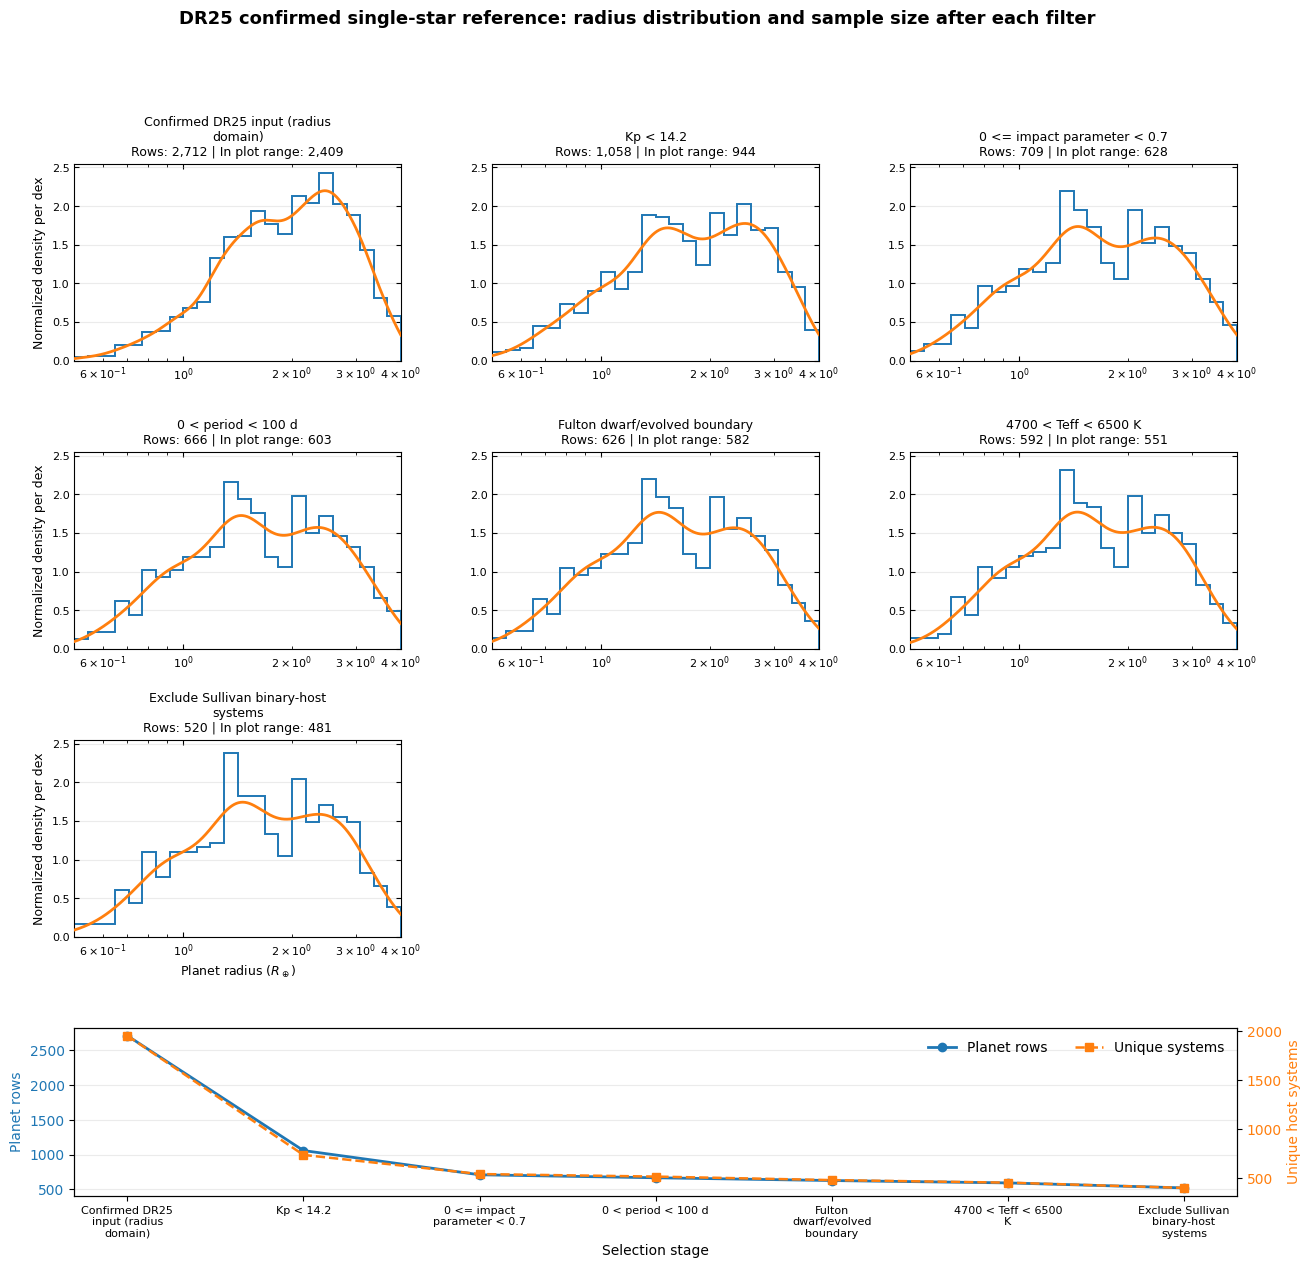

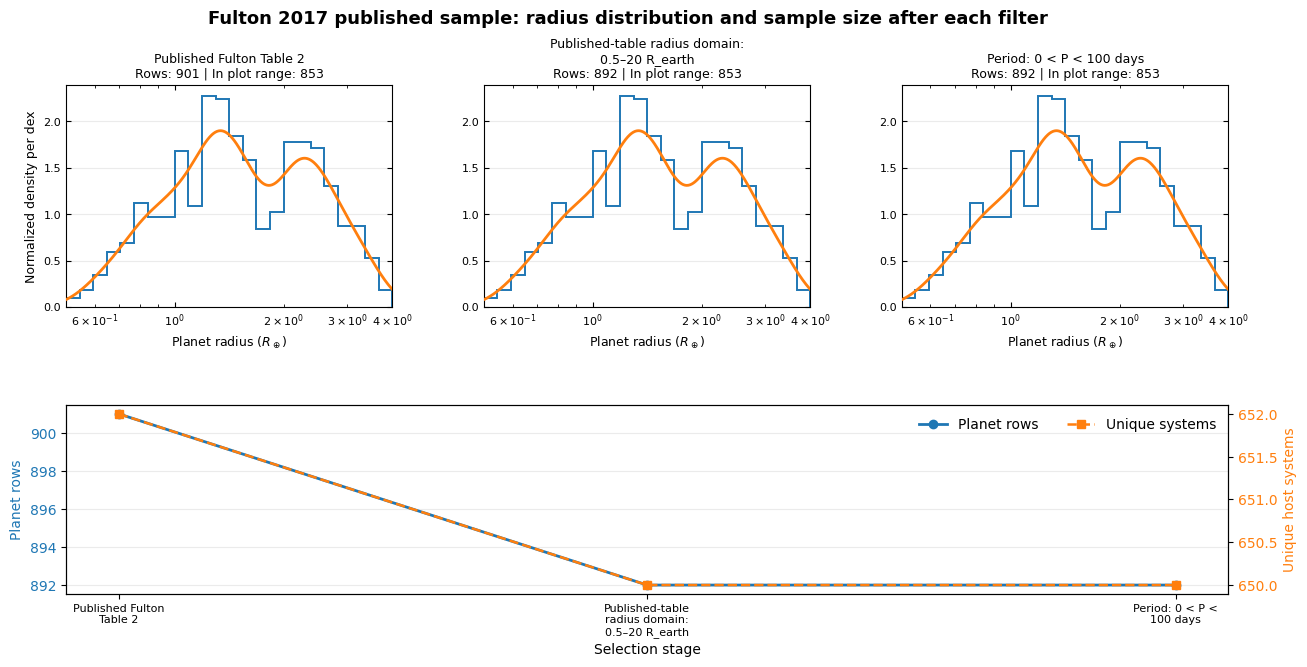

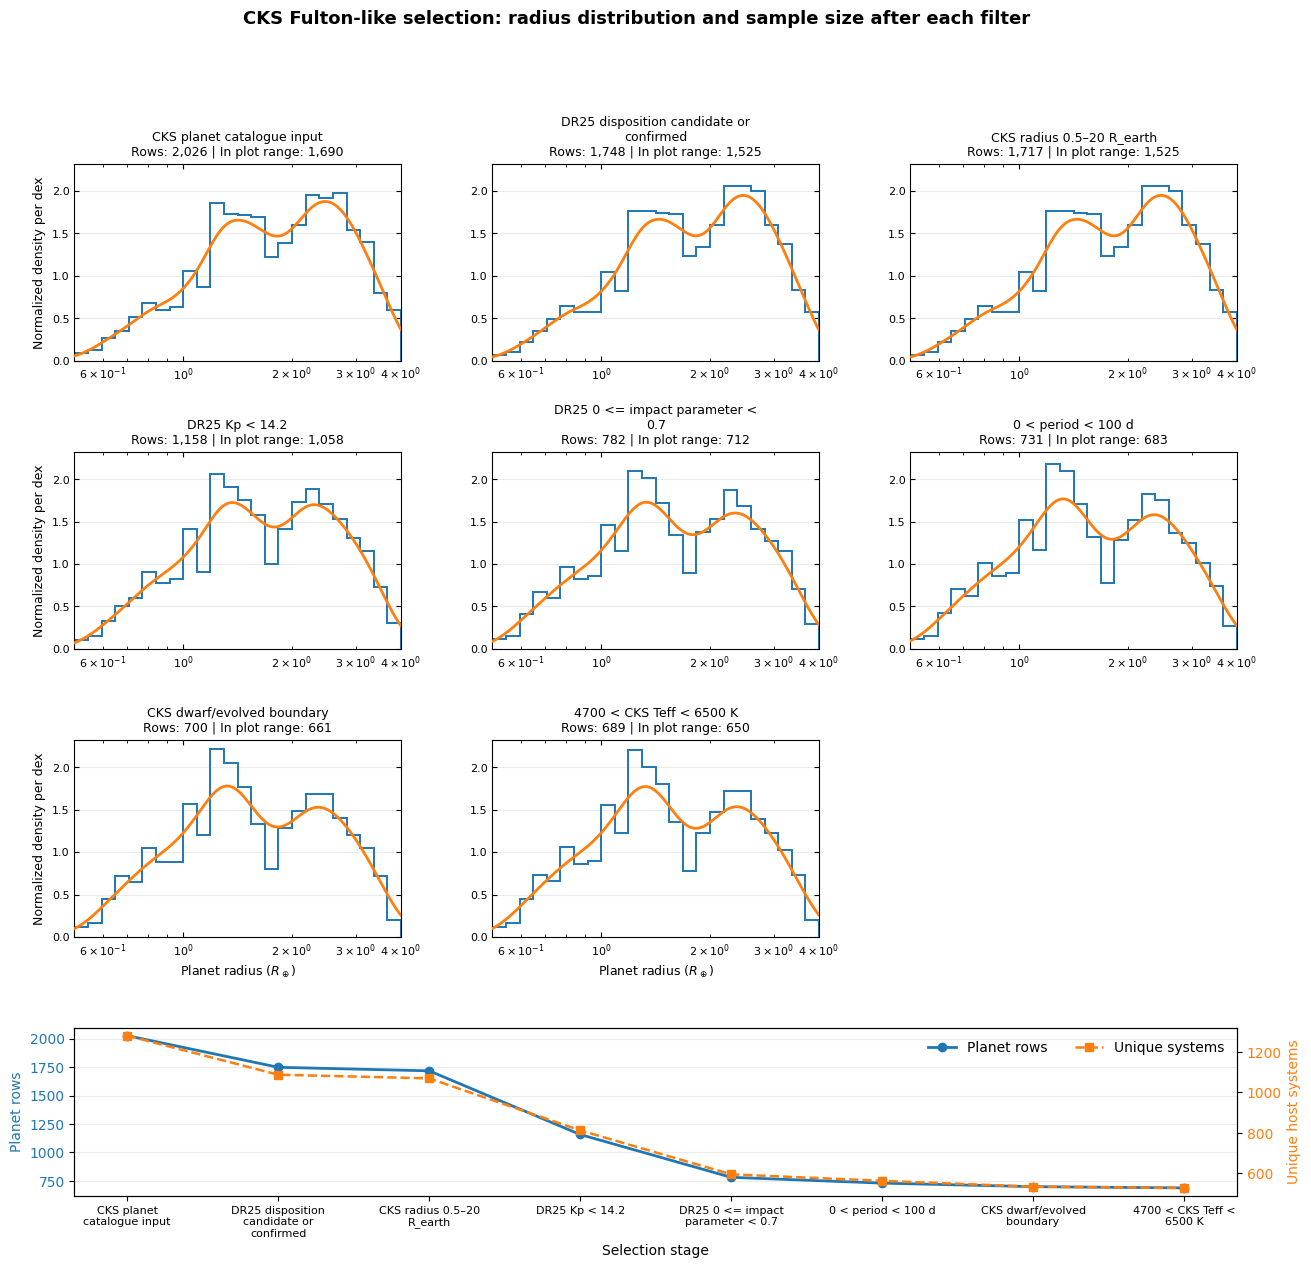

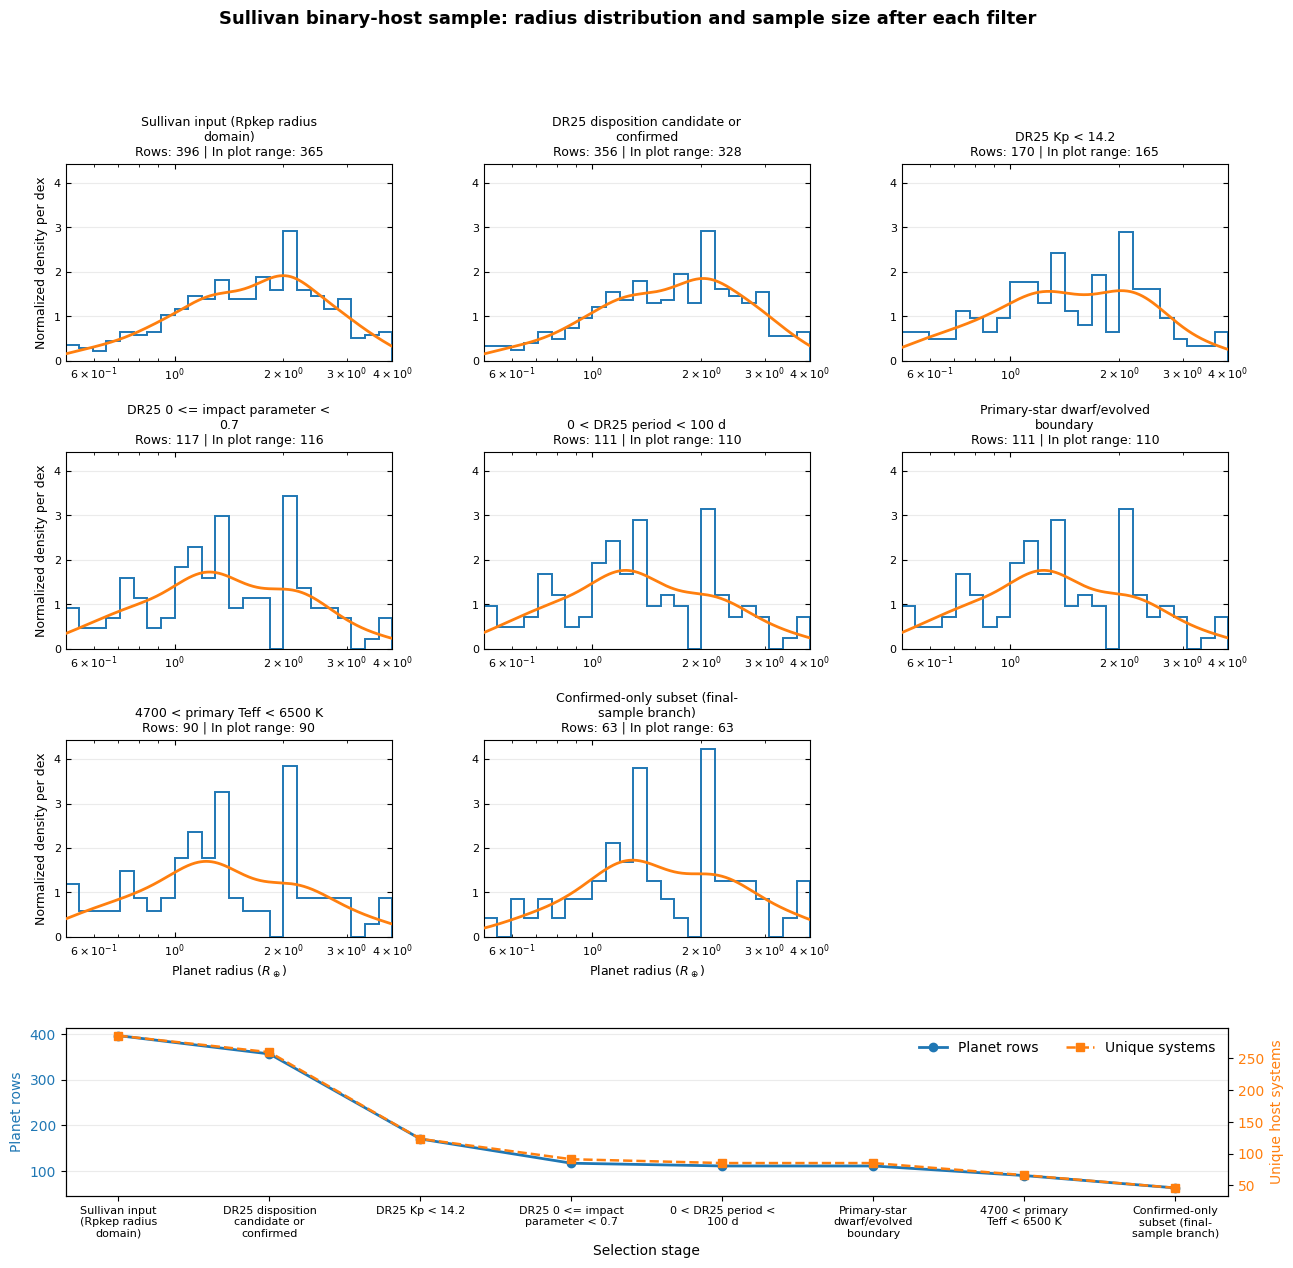

In [9]:
import textwrap

# --------------------------------------------------
# Helpers: radius distributions and sequential snapshots
# --------------------------------------------------

def histogram_per_dex(values, edges):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x) & (x >= edges[0]) & (x <= edges[-1])]

    if len(x) == 0:
        return np.zeros(len(edges) - 1)

    counts, _ = np.histogram(x, bins=edges)
    if counts.sum() == 0:
        return np.zeros(len(edges) - 1)

    return counts / counts.sum() / np.diff(np.log10(edges))


def kde_per_dex(values, grid, bandwidth_factor=1.0):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]

    if len(x) < 3 or np.unique(x).size < 2:
        return np.full_like(grid, np.nan, dtype=float)

    logx = np.log10(x)
    kde = gaussian_kde(
        logx,
        bw_method=lambda obj: obj.scotts_factor() * bandwidth_factor
    )
    return kde(np.log10(grid))


def build_cutflow_snapshots(frame, cuts, system_col='system_key',
                            initial_label='Input sample'):
    """Return the sample after the input stage and after each sequential cut."""
    current = frame.copy()
    snapshots = [(initial_label, current.copy())]

    for label, mask in cuts:
        aligned_mask = (
            pd.Series(mask, index=frame.index)
            .reindex(current.index)
            .fillna(False)
            .astype(bool)
        )
        current = current.loc[aligned_mask].copy()
        snapshots.append((label, current.copy()))

    return snapshots


# --------------------------------------------------
# Common radius grid
# --------------------------------------------------

RADIUS_EDGES = np.geomspace(PLOT_RMIN, PLOT_RMAX, N_BINS + 1)
RADIUS_GRID = np.geomspace(PLOT_RMIN, PLOT_RMAX, N_GRID)


# --------------------------------------------------
# Plot one catalogue: distribution at every filter stage
# plus planet/system counts after every stage
# --------------------------------------------------

def plot_filter_evolution(catalogue, snapshots, radius_col,
                          output_name, system_col='system_key'):
    n_stages = len(snapshots)
    ncols = 3
    nrows = int(np.ceil(n_stages / ncols))

    fig = plt.figure(figsize=(15, 3.4 * nrows + 3.2))
    gs = fig.add_gridspec(
        nrows + 1, ncols,
        height_ratios=[1] * nrows + [0.85],
        hspace=0.48,
        wspace=0.28
    )

    first_ax = None
    stage_labels = []
    planet_counts = []
    system_counts = []

    for i, (stage, frame) in enumerate(snapshots):
        row, col = divmod(i, ncols)

        if first_ax is None:
            ax = fig.add_subplot(gs[row, col])
            first_ax = ax
        else:
            ax = fig.add_subplot(
                gs[row, col],
                sharex=first_ax,
                sharey=first_ax
            )

        values = pd.to_numeric(
            frame[radius_col], errors='coerce'
        ).to_numpy(dtype=float)

        values = values[
            np.isfinite(values)
            & (values >= PLOT_RMIN)
            & (values <= PLOT_RMAX)
        ]

        # Outline-only histogram
        if len(values) > 0:
            hist = histogram_per_dex(values, RADIUS_EDGES)
            ax.stairs(
                hist,
                RADIUS_EDGES,
                color='C0',
                linewidth=1.4,
                fill=False,
                zorder=2
            )

            density = kde_per_dex(
                values, RADIUS_GRID, KDE_BANDWIDTH_FACTOR
            )
            if np.isfinite(density).any():
                ax.plot(
                    RADIUS_GRID,
                    density,
                    color='C1',
                    linewidth=2.0,
                    zorder=3,
                    label='KDE'
                )

        ax.set_xscale('log')
        ax.set_xlim(PLOT_RMIN, PLOT_RMAX)
        ax.set_title(
            f'{textwrap.fill(stage, 30)}\n'
            f'Rows: {len(frame):,} | In plot range: {len(values):,}',
            fontsize=9
        )
        ax.grid(axis='y', alpha=0.25)
        ax.tick_params(
            axis='both', which='both',
            direction='in', top=True, right=True,
            labelsize=8
        )

        if col == 0:
            ax.set_ylabel('Normalized density per dex', fontsize=9)
        if row == nrows - 1:
            ax.set_xlabel(r'Planet radius ($R_\oplus$)', fontsize=9)

        # Counts are for the full selected frame, not just plot-range radii.
        stage_labels.append(stage)
        planet_counts.append(len(frame))
        if system_col in frame.columns:
            system_counts.append(frame[system_col].nunique(dropna=True))
        else:
            system_counts.append(np.nan)

    # Hide unused distribution panels.
    for j in range(n_stages, nrows * ncols):
        row, col = divmod(j, ncols)
        ax = fig.add_subplot(gs[row, col])
        ax.set_visible(False)

    # Count subplot across the full figure width.
    count_ax = fig.add_subplot(gs[nrows, :])
    x = np.arange(n_stages)

    count_ax.plot(
        x, planet_counts,
        marker='o', linewidth=2,
        color='C0', label='Planet rows'
    )
    count_ax.set_ylabel('Planet rows', color='C0')
    count_ax.tick_params(axis='y', labelcolor='C0')
    count_ax.grid(axis='y', alpha=0.25)

    system_ax = count_ax.twinx()
    system_ax.plot(
        x, system_counts,
        marker='s', linewidth=1.8,
        linestyle='--',
        color='C1', label='Unique systems'
    )
    system_ax.set_ylabel('Unique host systems', color='C1')
    system_ax.tick_params(axis='y', labelcolor='C1')

    short_labels = [
        textwrap.fill(label, 18)
        for label in stage_labels
    ]
    count_ax.set_xticks(x)
    count_ax.set_xticklabels(
        short_labels, rotation=0, ha='center', fontsize=8
    )
    count_ax.set_xlabel('Selection stage')

    handles1, labels1 = count_ax.get_legend_handles_labels()
    handles2, labels2 = system_ax.get_legend_handles_labels()
    count_ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        frameon=False,
        loc='upper right',
        ncol=2
    )

    fig.suptitle(
        f'{catalogue}: radius distribution and sample size after each filter',
        fontsize=13,
        fontweight='bold',
        y=0.995
    )
    fig.savefig(
        OUTPUT / output_name,
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()


# --------------------------------------------------
# Build the filter-by-filter sample snapshots
# --------------------------------------------------

# DR25: confirmed planets, followed by the Fulton-like cuts and
# the removal of systems in the Sullivan binary-host list.
dr25_snapshots = build_cutflow_snapshots(
    DR25_confirmed_input,
    dr25_cuts(DR25_confirmed_input),
    initial_label='Confirmed DR25 input (radius domain)'
)
dr25_snapshots.append(
    ('Exclude Sullivan binary-host systems', DR25_confirmed_single.copy())
)

# Fulton: this published table is already filtered in the source paper.
fulton_snapshots = build_cutflow_snapshots(
    fulton,
    [
        ('Published-table radius domain: 0.5–20 R_earth',
         fulton['Rp_Fulton'].between(RADIUS_MIN, RADIUS_MAX)),
        ('Period: 0 < P < 100 days',
         fulton['Period_Fulton'].gt(0) & fulton['Period_Fulton'].lt(PERIOD_MAX)),
    ],
    initial_label='Published Fulton Table 2'
)

# CKS: apply the available Fulton-like cuts sequentially.
cks_snapshots = build_cutflow_snapshots(
    cks,
    cks_cuts,
    initial_label='CKS planet catalogue input'
)

# Sullivan: show candidate+confirmed filter progression, then the
# confirmed-only subset as a separate branch from the final parent sample.
sullivan_snapshots = build_cutflow_snapshots(
    sullivan_domain,
    sullivan_cuts,
    initial_label='Sullivan input (Rpkep radius domain)'
)
sullivan_snapshots.append(
    ('Confirmed-only subset (final-sample branch)',
     sullivan_confirmed.copy())
)


# --------------------------------------------------
# Make one simple filter-evolution figure per catalogue
# --------------------------------------------------

plot_filter_evolution(
    'DR25 confirmed single-star reference',
    dr25_snapshots,
    'Rp_DR25',
    '03_DR25_filter_evolution.png'
)

plot_filter_evolution(
    'Fulton 2017 published sample',
    fulton_snapshots,
    'Rp_Fulton',
    '04_Fulton_filter_evolution.png'
)

plot_filter_evolution(
    'CKS Fulton-like selection',
    cks_snapshots,
    'Rp_CKS',
    '05_CKS_filter_evolution.png'
)

plot_filter_evolution(
    'Sullivan binary-host sample',
    sullivan_snapshots,
    'Rppri',
    '06_Sullivan_filter_evolution.png'
)

## 10. Sullivan host-radius sensitivity (same planets, alternative radii)

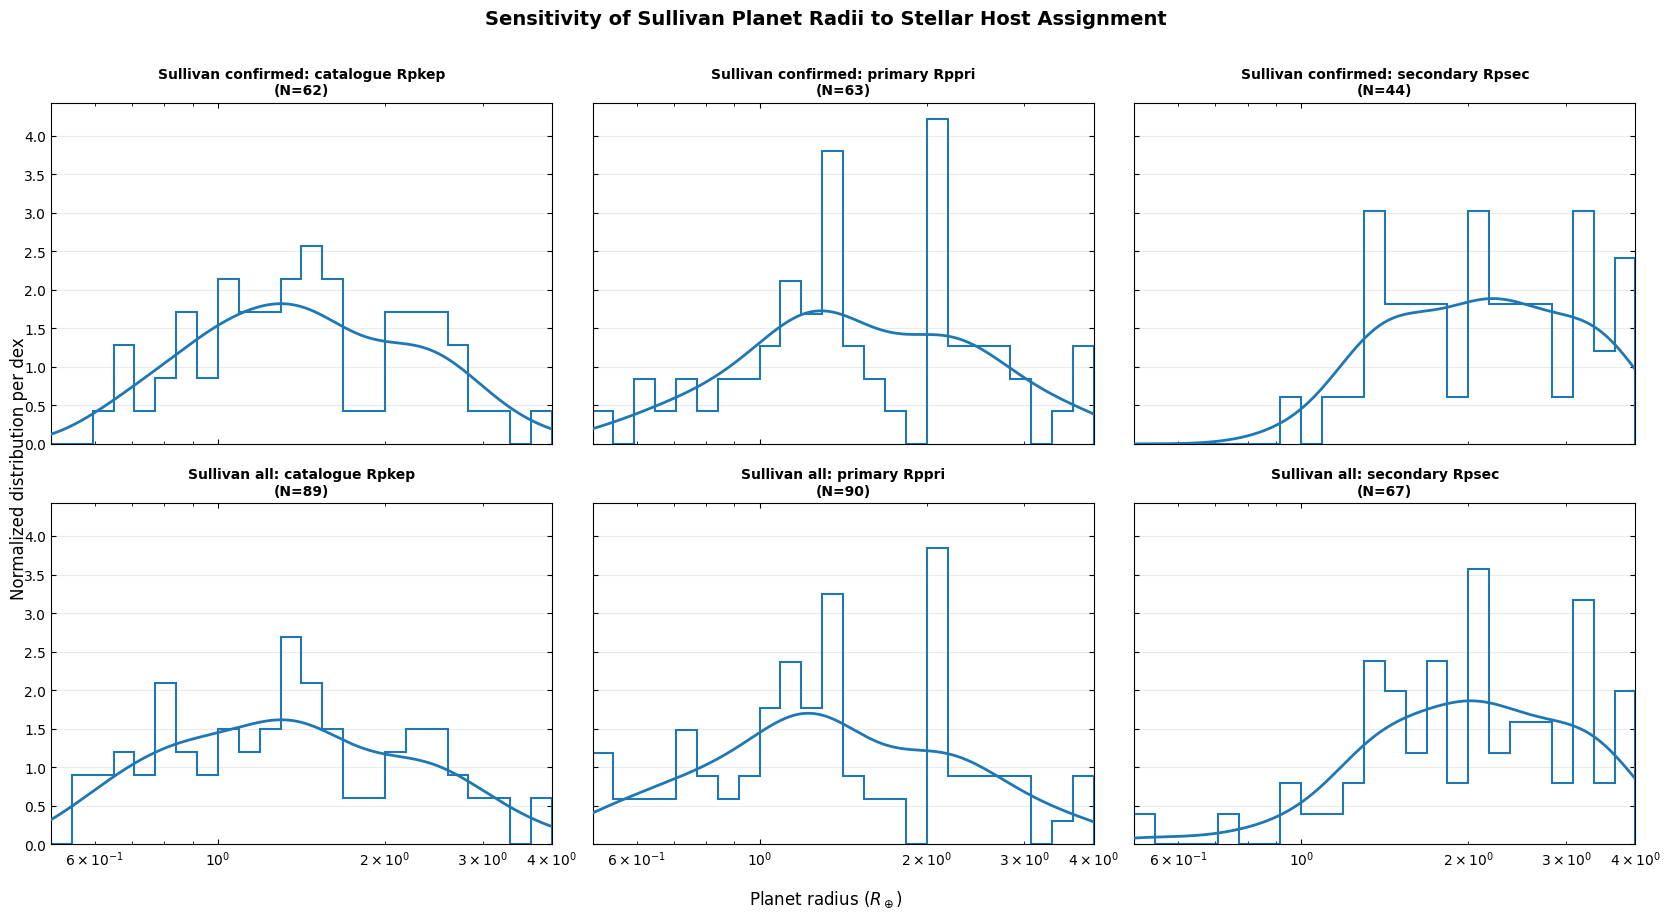

In [10]:

# This panel isolates the effect of the adopted stellar host on inferred radius.
# Rpkep, Rppri, and Rpsec are alternate radius estimates for the same objects;
# they are never concatenated as independent planets in the main comparison.

SULLIVAN_RADIUS_CASES = {
    'Sullivan confirmed: catalogue Rpkep': (sullivan_confirmed, 'Rpkep'),
    'Sullivan confirmed: primary Rppri': (sullivan_confirmed, 'Rppri'),
    'Sullivan confirmed: secondary Rpsec': (sullivan_confirmed, 'Rpsec'),
    'Sullivan all: catalogue Rpkep': (sullivan_candidate_confirmed, 'Rpkep'),
    'Sullivan all: primary Rppri': (sullivan_candidate_confirmed, 'Rppri'),
    'Sullivan all: secondary Rpsec': (sullivan_candidate_confirmed, 'Rpsec'),
}


# --------------------------------------------------
# Create 3-column x 2-row figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    sharex=True,
    sharey=True
)

axes = axes.flatten()


# --------------------------------------------------
# Plot each distribution separately
# --------------------------------------------------

for ax, (label, (frame, col)) in zip(
    axes, SULLIVAN_RADIUS_CASES.items()
):

    values = pd.to_numeric(
        frame[col],
        errors='coerce'
    ).to_numpy(dtype=float)

    values = values[
        np.isfinite(values)
        & (values >= PLOT_RMIN)
        & (values <= PLOT_RMAX)
    ]

    if len(values) < 3:
        warnings.warn(
            f'{label}: fewer than 3 valid radii; skipped.'
        )
        ax.set_visible(False)
        continue

    # Histogram outline only
    color = ax._get_lines.get_next_color()

    hist = histogram_per_dex(
        values,
        RADIUS_EDGES
    )

    ax.stairs(
        hist,
        RADIUS_EDGES,
        color=color,
        linewidth=1.5,
        fill=False,
        zorder=2
    )

    # KDE
    density = kde_per_dex(
        values,
        RADIUS_GRID,
        KDE_BANDWIDTH_FACTOR
    )

    if np.isfinite(density).any():
        ax.plot(
            RADIUS_GRID,
            density,
            color=color,
            linewidth=2.0,
            zorder=3,
            label='KDE'
        )

    # Panel formatting
    ax.set_xscale('log')
    ax.set_xlim(PLOT_RMIN, PLOT_RMAX)

    ax.set_title(
        f'{label}\n(N={len(values)})',
        fontsize=10,
        fontweight='bold'
    )

    ax.grid(
        axis='y',
        alpha=0.25
    )

    ax.tick_params(
        axis='both',
        which='both',
        direction='in',
        top=True,
        right=True
    )


# --------------------------------------------------
# Common formatting
# --------------------------------------------------

fig.supxlabel(
    r'Planet radius ($R_\oplus$)',
    fontsize=12
)

fig.supylabel(
    'Normalized distribution per dex',
    fontsize=12
)

fig.suptitle(
    'Sensitivity of Sullivan Planet Radii to Stellar Host Assignment',
    fontsize=14,
    fontweight='bold',
    y=1.01
)

fig.tight_layout()

# Save figure
fig.savefig(
    OUTPUT / '02_sullivan_host_radius_sensitivity.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 11. Export sample counts, cutflow, and filtered catalogues

In [11]:
POPULATION_SUMMARY.to_csv(OUTPUT / 'population_summary.csv', index=False)
ALL_CUTS.to_csv(OUTPUT / 'fulton_like_cutflow_all_catalogues.csv', index=False)
DR25_confirmed_single.to_csv(OUTPUT / 'dr25_confirmed_single_reference.csv', index=False)
fulton_selected.to_csv(OUTPUT / 'fulton_2017_published_selected.csv', index=False)
cks_selected.to_csv(OUTPUT / 'cks_fulton_like_selected.csv', index=False)
sullivan_confirmed.to_csv(OUTPUT / 'sullivan_confirmed_only_fulton_like.csv', index=False)
sullivan_candidate_confirmed.to_csv(OUTPUT / 'sullivan_candidate_confirmed_fulton_like.csv', index=False)

manifest = pd.DataFrame([
    {'catalogue': 'DR25', 'source': str(DR25_FILE), 'raw_rows': len(dr25_raw), 'selected_rows': len(DR25_confirmed_single), 'selected_systems': DR25_confirmed_single.system_key.nunique(), 'radius': 'Rp_DR25'},
    {'catalogue': 'Fulton 2017', 'source': 'VizieR J/AJ/154/109/table2 (published selected table)', 'raw_rows': len(fulton_raw), 'selected_rows': len(fulton_selected), 'selected_systems': fulton_selected.system_key.nunique(), 'radius': 'Rp_Fulton'},
    {'catalogue': 'CKS', 'source': 'VizieR J/AJ/154/108/table1 + table4', 'raw_rows': len(cks), 'selected_rows': len(cks_selected), 'selected_systems': cks_selected.system_key.nunique(), 'radius': 'Rp_CKS'},
    {'catalogue': 'Sullivan confirmed', 'source': f'{SULLIVAN_PLANETS_FILE} + {SULLIVAN_STARS_FILE} + DR25 join', 'raw_rows': len(sullivan_binary), 'selected_rows': len(sullivan_confirmed), 'selected_systems': sullivan_confirmed.system_key.nunique(), 'radius': 'Rppri'},
    {'catalogue': 'Sullivan candidate+confirmed', 'source': f'{SULLIVAN_PLANETS_FILE} + {SULLIVAN_STARS_FILE} + DR25 join', 'raw_rows': len(sullivan_binary), 'selected_rows': len(sullivan_candidate_confirmed), 'selected_systems': sullivan_candidate_confirmed.system_key.nunique(), 'radius': 'Rppri'},
])
manifest.to_csv(OUTPUT / 'input_and_selection_manifest.csv', index=False)

display(manifest)
print('\nSaved products to:', OUTPUT.resolve())
for p in sorted(OUTPUT.glob('*')):
    print(p.name)

,catalogue,source,raw_rows,selected_rows,selected_systems,radius
0,DR25,C:\Users\Lenovo\Downloads\bin\data\raw\nasa\na...,8054,520,395,Rp_DR25
1,Fulton 2017,VizieR J/AJ/154/109/table2 (published selected...,901,892,650,Rp_Fulton
2,CKS,VizieR J/AJ/154/108/table1 + table4,2026,689,527,Rp_CKS
3,Sullivan confirmed,C:\Users\Lenovo\Downloads\bin\data\raw\sulliva...,404,63,46,Rppri
4,Sullivan candidate+confirmed,C:\Users\Lenovo\Downloads\bin\data\raw\sulliva...,404,90,66,Rppri



Saved products to: C:\Users\Lenovo\Downloads\bin\outputs\fulton_filtered_distribution_comparison
.ipynb_checkpoints
02_sullivan_host_radius_sensitivity.png
03_DR25_filter_evolution.png
04_Fulton_filter_evolution.png
05_CKS_filter_evolution.png
06_Sullivan_filter_evolution.png
cks_fulton_like_selected.csv
dr25_confirmed_single_reference.csv
fulton_2017_published_selected.csv
fulton_like_cutflow_all_catalogues.csv
input_and_selection_manifest.csv
population_summary.csv
sullivan_candidate_confirmed_fulton_like.csv
sullivan_confirmed_only_fulton_like.csv


## 12. Interpretation and checks before scientific use

1. Compare both `N_planets` and `N_systems`. A value such as 92 must be identified as one of these units and tied to an explicit disposition/selection stage.
2. The Sullivan “confirmed-only” subset is selected by the DR25 *planet* disposition. It does not mean that a binary-star detection is candidate versus confirmed.
3. The 172-row candidate+confirmed sample should be checked against the printed post-cut result. If the count differs, inspect the sequential cutflow and the DR25 matching audit rather than hard-coding 172.
4. The Fulton 2017 table is already a selected subset. Only its available radius and period columns can be rechecked here. It is not an unfiltered parent catalogue.
5. CKS and Fulton are not independent planet populations: the Fulton table is drawn from the CKS programme. They are plotted separately because they correspond to the full CKS planet table versus the Fulton et al. published filtered sample.
6. The histogram and KDE show detected-planet distributions. Do not interpret the curves as completeness-corrected occurrence distributions.

### Data sources

- Fulton et al. (2017), VizieR `J/AJ/154/109/table2`: [catalogue ReadMe](https://cdsarc.cds.unistra.fr/viz-bin/ReadMe/J/AJ/154/109?format=html&tex=true).
- CKS Paper II, VizieR `J/AJ/154/108/table1` and `table4`.
- Sullivan et al. (2024), VizieR `J/AJ/168/129/sample` and `table5`.

The primary project notebook used for the adapted Sullivan/CKS cuts is `Binaries_Gap_Complete_Analysis(3).ipynb`.

7. The filter-evolution figures show the radius distribution at each sequential selection stage and the corresponding planet-row and unique-system counts. The count curves use the full selection-domain sample; the radius panels show only the configured plotting interval.

## 13. Raw-count radius histograms: single-star before/after and binary radius estimates

- **Single-star samples:** compare only the input sample (before selection) with the final selected sample (after selection), separately for DR25 and CKS.
- **Binary-host sample:** compare the three radius estimates for the same selected Sullivan planet rows: Kepler catalogue radius (`Rpkep`), primary-host radius (`Rppri`), and secondary-host radius (`Rpsec`).

All histograms show raw planet counts per radius bin. No normalization or KDE is applied.

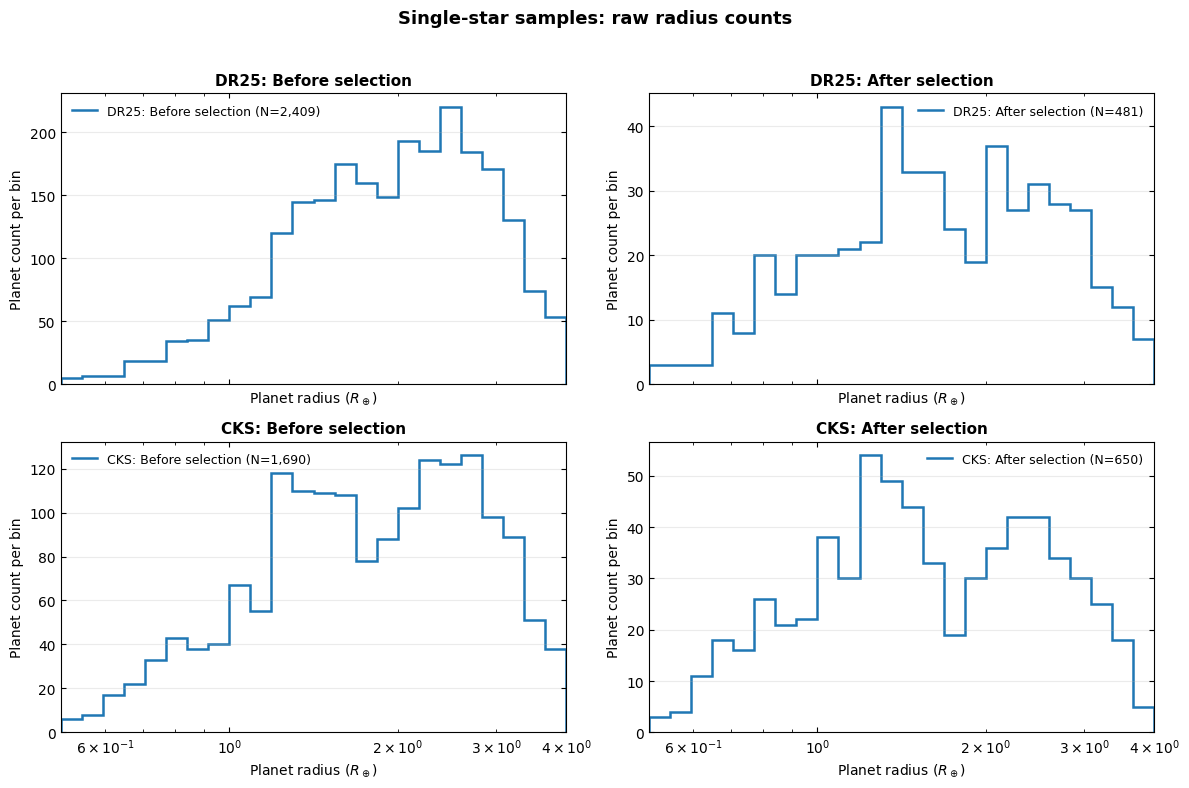

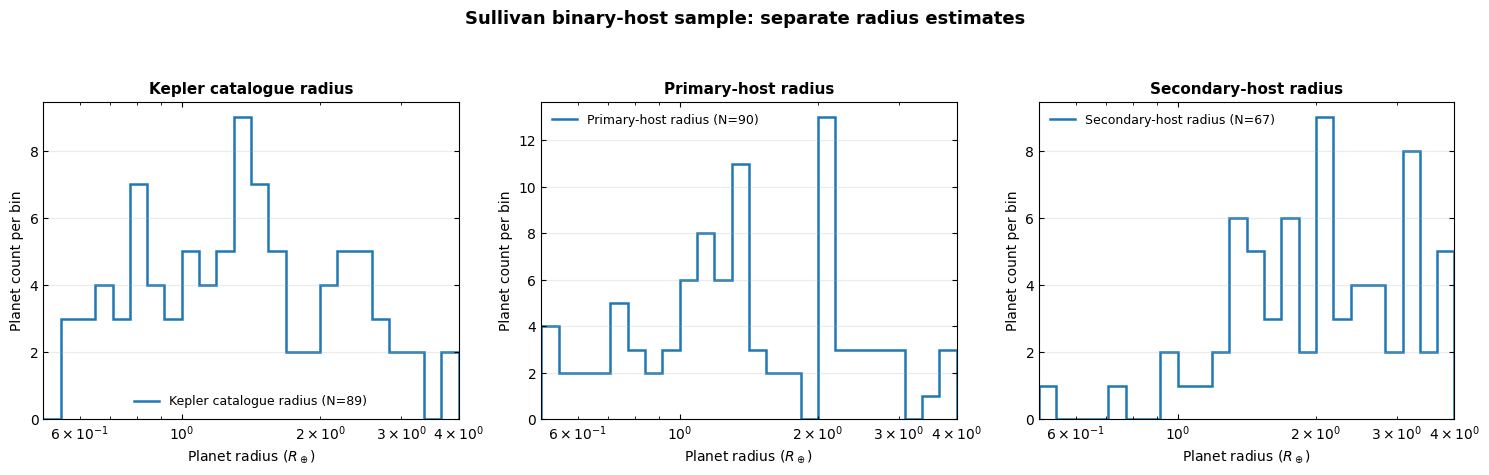

In [12]:

# --------------------------------------------------
# Raw-count histograms
# Separate subplots:
# 1. DR25 before selection
# 2. DR25 after selection
# 3. CKS before selection
# 4. CKS after selection
# 5. Binary-host: Kepler, primary, secondary radii
# --------------------------------------------------

def get_radius_values(frame, radius_col):
    values = pd.to_numeric(
        frame[radius_col], errors="coerce"
    ).to_numpy(dtype=float)

    return values[
        np.isfinite(values)
        & (values >= PLOT_RMIN)
        & (values <= PLOT_RMAX)
    ]


def add_count_histogram(ax, frame, radius_col, label):
    values = get_radius_values(frame, radius_col)
    counts, _ = np.histogram(values, bins=RADIUS_EDGES)

    ax.stairs(
        counts,
        RADIUS_EDGES,
        linewidth=1.8,
        fill=False,
        label=f"{label} (N={len(values):,})"
    )

    ax.set_xscale("log")
    ax.set_xlim(PLOT_RMIN, PLOT_RMAX)
    ax.set_xlabel(r"Planet radius ($R_\oplus$)")
    ax.set_ylabel("Planet count per bin")
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(
        axis="both", which="both",
        direction="in", top=True, right=True
    )
    ax.legend(frameon=False, fontsize=9)


# --------------------------------------------------
# Single-star samples: four separate subplots
# --------------------------------------------------

single_star_comparisons = [
    ("DR25: Before selection", DR25_confirmed_input, "Rp_DR25"),
    ("DR25: After selection", DR25_confirmed_single, "Rp_DR25"),
    ("CKS: Before selection", cks, "Rp_CKS"),
    ("CKS: After selection", cks_selected, "Rp_CKS"),
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    # sharey=True
)

for ax, (title, frame, radius_col) in zip(
    axes.flat, single_star_comparisons
):
    add_count_histogram(
        ax, frame, radius_col, title
    )
    ax.set_title(title, fontsize=11, fontweight="bold")

fig.suptitle(
    "Single-star samples: raw radius counts",
    fontsize=13,
    fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    OUTPUT / "07_single_star_separate_raw_count_histograms.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Binary-host sample: three separate subplots
# Same selected Sullivan planet rows
# --------------------------------------------------

binary_frame = sullivan_candidate_confirmed

binary_radius_cases = [
    ("Kepler catalogue radius", "Rpkep"),
    ("Primary-host radius", "Rppri"),
    ("Secondary-host radius", "Rpsec"),
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.8),
    sharex=True,
    # sharey=True
)

for ax, (title, radius_col) in zip(
    axes, binary_radius_cases
):
    add_count_histogram(
        ax, binary_frame, radius_col, title
    )
    ax.set_title(title, fontsize=11, fontweight="bold")

fig.suptitle(
    "Sullivan binary-host sample: separate radius estimates",
    fontsize=13,
    fontweight="bold"
)
fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    OUTPUT / "08_sullivan_binary_separate_raw_count_histograms.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_5376\4242629798.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  host["planet_key"] = (


BINARY: 63 planets | 46 systems
SINGLE: 520 planets | 395 systems
Binary planets without valid host probabilities: 0


,Population,F_valley
0,Binary: catalogue,0.166667
1,Binary: primary,0.400000
2,Binary: secondary,0.300000
3,Binary: probability marginalised,0.380929
4,Apparent single,0.320442


Delta F_valley = 0.06049


Host-assignment draws:   0%|          | 0/5000 [00:00<?, ?draw/s]

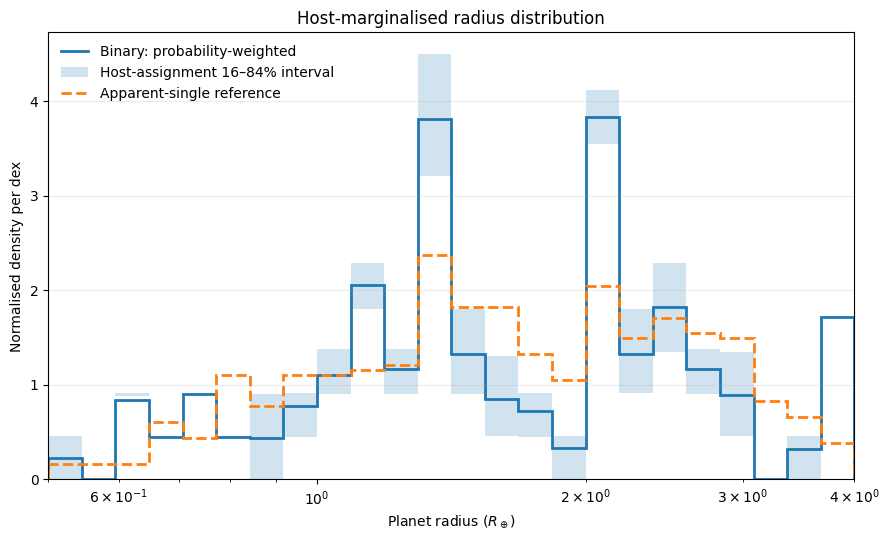

System-level subsampling:   0%|          | 0/10000 [00:00<?, ?sample/s]

,N_draws,N_valid,N_systems_per_draw,median_planets_per_draw,N_planets_16,N_planets_84,F_2.5,F_16,F_median,F_84,F_97.5,F_binary_marginal,empirical_two_sided_tail_fraction
0,10000,10000,46,60.0,56.0,65.0,0.136364,0.222222,0.318182,0.421053,0.526316,0.380929,0.556


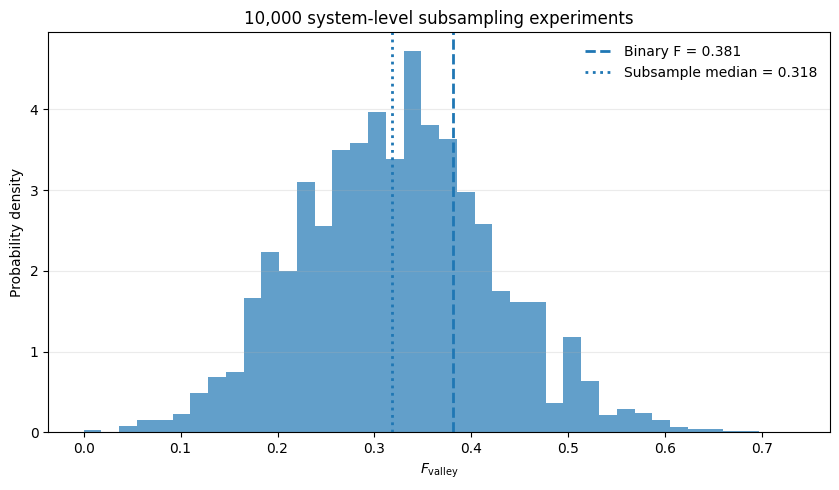

System bootstrap (10,000 resamples):   0%|          | 0/10000 [00:00<?, ?resample/s]

System bootstrap (10,000 resamples):   0%|          | 0/10000 [00:00<?, ?resample/s]

,Median,CI_68_low,CI_68_high,CI_95_low,CI_95_high
Binary,0.379310,0.285714,0.470588,0.200000,0.562500
Apparent single,0.320000,0.284974,0.356250,0.251429,0.392473
Delta F_valley,0.057971,-0.039570,0.155051,-0.133855,0.251658


P(Delta F > 0): 0.72
P(Delta F < 0): 0.2773


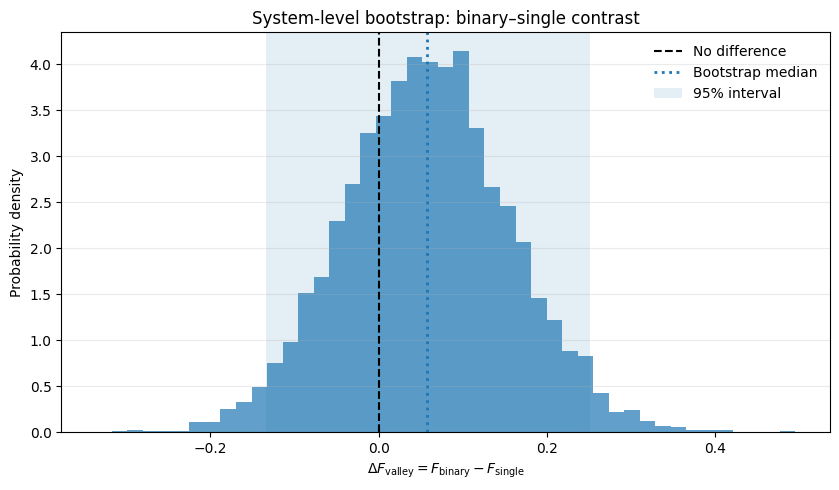


========== FINAL ANALYSIS ==========

F_valley:
                      Population  F_valley
               Binary: catalogue  0.166667
                 Binary: primary  0.400000
               Binary: secondary  0.300000
Binary: probability marginalised  0.380929
                 Apparent single  0.320442

Finite-sample experiment:
 N_draws  N_valid  N_systems_per_draw  median_planets_per_draw  N_planets_16  N_planets_84    F_2.5     F_16  F_median     F_84   F_97.5  F_binary_marginal  empirical_two_sided_tail_fraction
   10000    10000                  46                     60.0          56.0          65.0 0.136364 0.222222  0.318182 0.421053 0.526316           0.380929                              0.556

System-level bootstrap:
                   Median  CI_68_low  CI_68_high  CI_95_low  CI_95_high
Binary           0.379310   0.285714    0.470588   0.200000    0.562500
Apparent single  0.320000   0.284974    0.356250   0.251429    0.392473
Delta F_valley   0.057971  -0.039570    0.1

In [14]:
# ============================================================
# BINARY RADIUS GAP — PUBLICATION ANALYSIS
# 1. F_valley estimator
# 2. Probability-marginalised radius distribution
# 3. 10,000 system-level subsampling experiment
# 4. System-level bootstrap
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
# Prerequisites from earlier notebook cells:
# ROOT, normalize_planet_key, sullivan_confirmed, DR25_confirmed_single
# must already be defined.

RVALLEY_A = 2.25
RVALLEY_B = -0.26

VALLEY_WIDTH = 0.20
CONTROL_WIDTH = 0.60

RADIUS_RANGE = (0.5, 4.0)
N_BINS = 24

N_HOST_DRAWS = 5000
N_SUBSAMPLES = 10000
N_BOOTSTRAP = 10000

SEED = 20261105
rng = np.random.default_rng(SEED)

PROCESSED = ROOT / "data" / "processed"
HOST_FILE = PROCESSED / "binary_host_probability_catalog.csv"

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

if not HOST_FILE.exists():
    raise FileNotFoundError(
        f"Run Notebook 05 first. Missing: {HOST_FILE}"
    )

host = pd.read_csv(HOST_FILE, low_memory=False)

host["planet_key"] = (
    host["KOIpl"]
    .map(normalize_planet_key)
    .astype("string")
)

host["p_pri"] = pd.to_numeric(host["p_pri"], errors="coerce")
host["p_sec"] = pd.to_numeric(host["p_sec"], errors="coerce")

host = host[
    ["planet_key", "p_pri", "p_sec"]
].dropna(subset=["planet_key"])

assert host["planet_key"].is_unique

binary = sullivan_confirmed.copy()

if "planet_key" not in binary:
    binary["planet_key"] = (
        binary["KOIpl"]
        .map(normalize_planet_key)
        .astype("string")
    )

binary = binary.merge(
    host,
    on="planet_key",
    how="left",
    validate="one_to_one"
)

numeric_cols = [
    "Rppri", "Rpsec", "Rpkep",
    "Period_DR25", "p_pri", "p_sec"
]

for col in numeric_cols:
    binary[col] = pd.to_numeric(binary[col], errors="coerce")

binary = binary.loc[
    np.isfinite(binary["Rppri"])
    & np.isfinite(binary["Rpsec"])
    & np.isfinite(binary["Period_DR25"])
    & np.isfinite(binary["p_pri"])
    & np.isfinite(binary["p_sec"])
    & binary["Period_DR25"].gt(0)
    & binary["system_key"].notna()
].copy()

assert np.allclose(
    binary["p_pri"] + binary["p_sec"],
    1.0,
    atol=1e-6
)

single = DR25_confirmed_single.copy()

single["Rp_DR25"] = pd.to_numeric(
    single["Rp_DR25"], errors="coerce"
)
single["Period_DR25"] = pd.to_numeric(
    single["Period_DR25"], errors="coerce"
)

single = single.loc[
    np.isfinite(single["Rp_DR25"])
    & np.isfinite(single["Period_DR25"])
    & single["Rp_DR25"].gt(0)
    & single["Period_DR25"].gt(0)
    & single["system_key"].notna()
].copy()

print("BINARY:", len(binary), "planets |",
      binary.system_key.nunique(), "systems")

print("SINGLE:", len(single), "planets |",
      single.system_key.nunique(), "systems")

print("Binary planets without valid host probabilities:",
      len(sullivan_confirmed) - len(binary))


# ------------------------------------------------------------
# 2. F_VALLEY ESTIMATOR
# ------------------------------------------------------------

def valley_radius(period):

    period = np.asarray(period, dtype=float)

    return (
        RVALLEY_A
        + RVALLEY_B * np.log10(period)
    )


def fvalley(radius, period, weights=None):

    radius = np.asarray(radius, dtype=float)
    period = np.asarray(period, dtype=float)

    if weights is None:
        weights = np.ones(len(radius))

    weights = np.asarray(weights, dtype=float)

    valid = (
        np.isfinite(radius)
        & (radius > 0)
        & np.isfinite(period)
        & (period > 0)
        & np.isfinite(weights)
        & (weights >= 0)
    )

    radius = radius[valid]
    period = period[valid]
    weights = weights[valid]

    if len(radius) == 0:
        return np.nan

    rv = valley_radius(period)
    distance = np.abs(radius - rv)

    narrow = distance <= VALLEY_WIDTH
    broad = distance <= CONTROL_WIDTH

    denominator = weights[broad].sum()

    if denominator <= 0:
        return np.nan

    return weights[narrow].sum() / denominator


def fvalley_binary_marginal(frame):

    period = frame["Period_DR25"].to_numpy()

    radius = np.concatenate([
        frame["Rppri"].to_numpy(),
        frame["Rpsec"].to_numpy()
    ])

    periods = np.concatenate([period, period])

    weights = np.concatenate([
        frame["p_pri"].to_numpy(),
        frame["p_sec"].to_numpy()
    ])

    return fvalley(radius, periods, weights)


def fvalley_binary_hostdraw(frame, random_state):

    choose_primary = (
        random_state.random(len(frame))
        < frame["p_pri"].to_numpy()
    )

    radius = np.where(
        choose_primary,
        frame["Rppri"].to_numpy(),
        frame["Rpsec"].to_numpy()
    )

    return fvalley(
        radius,
        frame["Period_DR25"].to_numpy()
    )


# Five radius treatments

F_catalogue = fvalley(
    binary["Rpkep"],
    binary["Period_DR25"]
)

F_primary = fvalley(
    binary["Rppri"],
    binary["Period_DR25"]
)

F_secondary = fvalley(
    binary["Rpsec"],
    binary["Period_DR25"]
)

F_marginal = fvalley_binary_marginal(binary)

F_single = fvalley(
    single["Rp_DR25"],
    single["Period_DR25"]
)

FVALLEY_RESULTS = pd.DataFrame({
    "Population": [
        "Binary: catalogue",
        "Binary: primary",
        "Binary: secondary",
        "Binary: probability marginalised",
        "Apparent single"
    ],
    "F_valley": [
        F_catalogue,
        F_primary,
        F_secondary,
        F_marginal,
        F_single
    ]
})

display(FVALLEY_RESULTS)

DELTA_F = F_marginal - F_single

print(f"Delta F_valley = {DELTA_F:.5f}")


# ------------------------------------------------------------
# 3. PROBABILITY-MARGINALISED RADIUS HISTOGRAM
# ------------------------------------------------------------

edges = np.geomspace(
    RADIUS_RANGE[0],
    RADIUS_RANGE[1],
    N_BINS + 1
)

widths = np.diff(np.log10(edges))

# Exact probability-weighted histogram.
radii = np.concatenate([
    binary["Rppri"].to_numpy(),
    binary["Rpsec"].to_numpy()
])

weights = np.concatenate([
    binary["p_pri"].to_numpy(),
    binary["p_sec"].to_numpy()
])

counts, _ = np.histogram(
    radii,
    bins=edges,
    weights=weights
)

weighted_density = (
    counts / counts.sum() / widths
)

# Posterior realisations of host assignments.
# Each planet contributes exactly once in each realisation.

host_histograms = []

p_primary = binary["p_pri"].to_numpy()
rp_primary = binary["Rppri"].to_numpy()
rp_secondary = binary["Rpsec"].to_numpy()

for _ in tqdm(
    range(N_HOST_DRAWS),
    desc="Host-assignment draws",
    unit="draw"
):

    choose_primary = rng.random(len(binary)) < p_primary

    drawn_radius = np.where(
        choose_primary,
        rp_primary,
        rp_secondary
    )

    counts_draw, _ = np.histogram(
        drawn_radius,
        bins=edges
    )

    if counts_draw.sum() > 0:

        density_draw = (
            counts_draw
            / counts_draw.sum()
            / widths
        )

        host_histograms.append(density_draw)

host_histograms = np.asarray(host_histograms)

hist_lo, hist_med, hist_hi = np.percentile(
    host_histograms,
    [16, 50, 84],
    axis=0
)

# Apparent-single reference histogram.

single_counts, _ = np.histogram(
    single["Rp_DR25"],
    bins=edges
)

single_density = (
    single_counts
    / single_counts.sum()
    / widths
)

# Plot.

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.stairs(
    weighted_density,
    edges,
    linewidth=2,
    label="Binary: probability-weighted"
)

ax.fill_between(
    edges[:-1],
    hist_lo,
    hist_hi,
    step="post",
    alpha=0.20,
    label="Host-assignment 16–84% interval"
)

ax.stairs(
    single_density,
    edges,
    linewidth=2,
    linestyle="--",
    label="Apparent-single reference"
)

ax.set_xscale("log")
ax.set_xlim(*RADIUS_RANGE)

ax.set_xlabel(r"Planet radius ($R_\oplus$)")
ax.set_ylabel("Normalised density per dex")

ax.set_title("Host-marginalised radius distribution")

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. 10,000-DRAW SYSTEM-LEVEL SUBSAMPLING
# ------------------------------------------------------------
#
# Draw 46 reference systems, retaining all their planets.
# Planet count varies naturally; this preserves system multiplicity.
#
# This is an initial finite-sample diagnostic, not yet a
# covariate-matched null experiment.
# ------------------------------------------------------------

single_groups = {
    sid: group.copy()
    for sid, group in single.groupby("system_key")
}

system_ids = np.array(list(single_groups.keys()), dtype=object)

N_SYSTEMS_TARGET = binary.system_key.nunique()

if N_SYSTEMS_TARGET > len(system_ids):
    raise ValueError("Insufficient reference systems.")

subsample_F = np.full(N_SUBSAMPLES, np.nan)
subsample_N = np.zeros(N_SUBSAMPLES, dtype=int)

for i in tqdm(
    range(N_SUBSAMPLES),
    desc="System-level subsampling",
    unit="sample"
):

    selected = rng.choice(
        system_ids,
        size=N_SYSTEMS_TARGET,
        replace=False
    )

    sample = pd.concat(
        [single_groups[sid] for sid in selected],
        ignore_index=True
    )

    subsample_N[i] = len(sample)

    subsample_F[i] = fvalley(
        sample["Rp_DR25"],
        sample["Period_DR25"]
    )

valid_F = subsample_F[np.isfinite(subsample_F)]

p_lower = np.mean(valid_F <= F_marginal)

p_two_sided = min(
    1.0,
    2.0 * min(p_lower, 1.0 - p_lower)
)

SUBSAMPLE_SUMMARY = pd.DataFrame([{
    "N_draws": N_SUBSAMPLES,
    "N_valid": len(valid_F),
    "N_systems_per_draw": N_SYSTEMS_TARGET,
    "median_planets_per_draw": np.median(subsample_N),
    "N_planets_16": np.percentile(subsample_N, 16),
    "N_planets_84": np.percentile(subsample_N, 84),
    "F_2.5": np.percentile(valid_F, 2.5),
    "F_16": np.percentile(valid_F, 16),
    "F_median": np.median(valid_F),
    "F_84": np.percentile(valid_F, 84),
    "F_97.5": np.percentile(valid_F, 97.5),
    "F_binary_marginal": F_marginal,
    "empirical_two_sided_tail_fraction": p_two_sided
}])

display(SUBSAMPLE_SUMMARY)

fig, ax = plt.subplots(figsize=(8.5, 5))

ax.hist(
    valid_F,
    bins=40,
    density=True,
    alpha=0.7
)

ax.axvline(
    F_marginal,
    linestyle="--",
    linewidth=2,
    label=f"Binary F = {F_marginal:.3f}"
)

ax.axvline(
    np.median(valid_F),
    linestyle=":",
    linewidth=2,
    label=f"Subsample median = {np.median(valid_F):.3f}"
)

ax.set_xlabel(r"$F_{\rm valley}$")
ax.set_ylabel("Probability density")

ax.set_title("10,000 system-level subsampling experiments")

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. SYSTEM-LEVEL BOOTSTRAP
# ------------------------------------------------------------

def system_bootstrap(frame, statistic, n_boot, random_state):

    groups = {
        sid: group.copy()
        for sid, group in frame.groupby("system_key")
    }

    ids = np.array(list(groups.keys()), dtype=object)

    results = np.full(n_boot, np.nan)

    for b in tqdm(
        range(n_boot),
        desc=f"System bootstrap ({n_boot:,} resamples)",
        unit="resample"
    ):

        selected = random_state.choice(
            ids,
            size=len(ids),
            replace=True
        )

        boot = pd.concat(
            [groups[sid] for sid in selected],
            ignore_index=True
        )

        results[b] = statistic(boot, random_state)

    return results


def binary_statistic(frame, random_state):

    # Host assignment is redrawn within each cluster-bootstrap sample.
    return fvalley_binary_hostdraw(frame, random_state)


def single_statistic(frame, random_state):

    return fvalley(
        frame["Rp_DR25"],
        frame["Period_DR25"]
    )


binary_boot = system_bootstrap(
    binary,
    binary_statistic,
    N_BOOTSTRAP,
    rng
)

single_boot = system_bootstrap(
    single,
    single_statistic,
    N_BOOTSTRAP,
    rng
)

valid = (
    np.isfinite(binary_boot)
    & np.isfinite(single_boot)
)

binary_boot = binary_boot[valid]
single_boot = single_boot[valid]

delta_boot = binary_boot - single_boot


# Summaries and confidence intervals.

def bootstrap_summary(values):

    return {
        "Median": np.median(values),
        "CI_68_low": np.percentile(values, 16),
        "CI_68_high": np.percentile(values, 84),
        "CI_95_low": np.percentile(values, 2.5),
        "CI_95_high": np.percentile(values, 97.5)
    }


BOOTSTRAP_RESULTS = pd.DataFrame({
    "Binary": bootstrap_summary(binary_boot),
    "Apparent single": bootstrap_summary(single_boot),
    "Delta F_valley": bootstrap_summary(delta_boot)
}).T

display(BOOTSTRAP_RESULTS)

print(
    "P(Delta F > 0):",
    np.mean(delta_boot > 0)
)

print(
    "P(Delta F < 0):",
    np.mean(delta_boot < 0)
)


# Bootstrap distribution of the difference.

fig, ax = plt.subplots(figsize=(8.5, 5))

ax.hist(
    delta_boot,
    bins=45,
    density=True,
    alpha=0.7
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    label="No difference"
)

ax.axvline(
    np.median(delta_boot),
    linestyle=":",
    linewidth=2,
    label="Bootstrap median"
)

ax.axvspan(
    np.percentile(delta_boot, 2.5),
    np.percentile(delta_boot, 97.5),
    alpha=0.12,
    label="95% interval"
)

ax.set_xlabel(
    r"$\Delta F_{\rm valley}=F_{\rm binary}-F_{\rm single}$"
)

ax.set_ylabel("Probability density")

ax.set_title("System-level bootstrap: binary–single contrast")

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. FINAL RESULTS
# ------------------------------------------------------------

print("\n========== FINAL ANALYSIS ==========\n")

print("F_valley:")
print(FVALLEY_RESULTS.to_string(index=False))

print("\nFinite-sample experiment:")
print(SUBSAMPLE_SUMMARY.to_string(index=False))

print("\nSystem-level bootstrap:")
print(BOOTSTRAP_RESULTS)

print("\nValid subsampling draws:", len(valid_F))
print("Valid bootstrap draws:", len(delta_boot))

print("\nNOTE:")
print("1. Subsampling retains complete systems, so planet counts vary.")
print("2. Subsampling is not yet covariate-matched.")
print("3. Bootstrap includes host-assignment draws but not radius-error draws.")
print("4. These are detected-planet distributions, not intrinsic occurrence rates.")

  0%|          | 0/5000 [00:00<?, ?it/s]

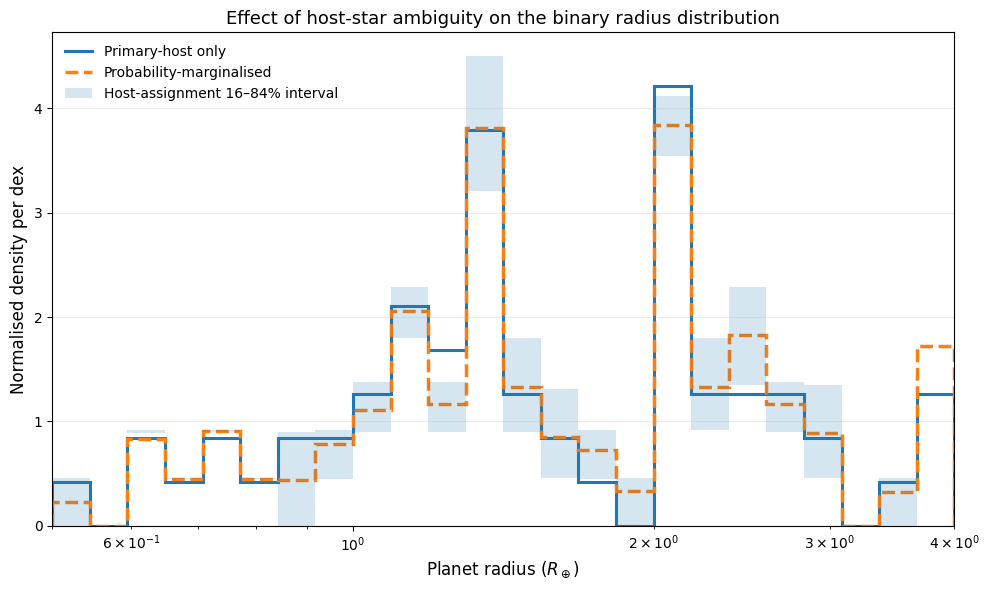

========== HOST AMBIGUITY EFFECT ==========
Primary-only F_valley       : 0.4000
Marginalised F_valley       : 0.3809
Change in F_valley          : -0.0191
Relative change             : -4.77%


In [16]:
# ============================================================
# FIGURE: EFFECT OF HOST AMBIGUITY ON THE RADIUS DISTRIBUTION
# Primary-only vs probability-marginalised
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

N_BINS = 24
N_DRAWS = 5000
SEED = 20261105

rng = np.random.default_rng(SEED)

edges = np.geomspace(0.5, 4.0, N_BINS + 1)
log_widths = np.diff(np.log10(edges))

rp_pri = binary["Rppri"].to_numpy(dtype=float)
rp_sec = binary["Rpsec"].to_numpy(dtype=float)

p_pri = binary["p_pri"].to_numpy(dtype=float)
p_sec = binary["p_sec"].to_numpy(dtype=float)

period = binary["Period_DR25"].to_numpy(dtype=float)

# ------------------------------------------------------------
# 2. Primary-only histogram
# ------------------------------------------------------------

counts_primary, _ = np.histogram(
    rp_pri,
    bins=edges
)

density_primary = (
    counts_primary
    / counts_primary.sum()
    / log_widths
)

# ------------------------------------------------------------
# 3. Probability-marginalised histogram
# ------------------------------------------------------------

counts_marginal, _ = np.histogram(
    np.concatenate([rp_pri, rp_sec]),
    bins=edges,
    weights=np.concatenate([p_pri, p_sec])
)

density_marginal = (
    counts_marginal
    / counts_marginal.sum()
    / log_widths
)

# ------------------------------------------------------------
# 4. Host-assignment realisations
# ------------------------------------------------------------

draw_histograms = []

for _ in tqdm(range(N_DRAWS)):

    choose_primary = rng.random(len(binary)) < p_pri

    rp_draw = np.where(
        choose_primary,
        rp_pri,
        rp_sec
    )

    counts, _ = np.histogram(
        rp_draw,
        bins=edges
    )

    density = (
        counts / counts.sum() / log_widths
    )

    draw_histograms.append(density)

draw_histograms = np.asarray(draw_histograms)

draw_lo, draw_med, draw_hi = np.percentile(
    draw_histograms,
    [16, 50, 84],
    axis=0
)

# ------------------------------------------------------------
# 5. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.stairs(
    density_primary,
    edges,
    linewidth=2.2,
    label="Primary-host only"
)

ax.stairs(
    density_marginal,
    edges,
    linewidth=2.5,
    linestyle="--",
    label="Probability-marginalised"
)

ax.fill_between(
    edges[:-1],
    draw_lo,
    draw_hi,
    step="post",
    alpha=0.18,
    label="Host-assignment 16–84% interval"
)

ax.set_xscale("log")
ax.set_xlim(0.5, 4.0)

ax.set_xlabel(r"Planet radius ($R_\oplus$)", fontsize=12)
ax.set_ylabel("Normalised density per dex", fontsize=12)

ax.set_title(
    "Effect of host-star ambiguity on the binary radius distribution",
    fontsize=13
)

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Quantify the change
# ------------------------------------------------------------

F_primary_new = fvalley(
    rp_pri,
    period
)

F_marginal_new = fvalley_binary_marginal(binary)

print("========== HOST AMBIGUITY EFFECT ==========")

print(f"Primary-only F_valley       : {F_primary_new:.4f}")
print(f"Marginalised F_valley       : {F_marginal_new:.4f}")

print(
    f"Change in F_valley          : "
    f"{F_marginal_new - F_primary_new:+.4f}"
)

print(
    f"Relative change             : "
    f"{100 * (F_marginal_new/F_primary_new - 1):+.2f}%"
)